<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/26_QML_Model_Extraction_Theft/QNN_ModelExtraction_SplitCoTeaching_Fu2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Split co-teaching against a noisy QNN-as-a-Service: Fu and Chen (2024) step by step

This notebook re-implements, runs and checks the attack of

> Zhenxiao Fu and Fan Chen (Department of Intelligent Systems Engineering, Indiana University Bloomington),
> "Quantum Neural Network Extraction Attack via Split Co-Teaching",
> arXiv:2409.02207 [quant-ph], v1 September 2024, v2 9 January 2025. https://arxiv.org/abs/2409.02207

The paper publishes no code. Everything below is written from the method as the paper describes it.

**What the notebook does.** A *victim* quantum neural network (QNN) is trained and "deployed" as a QNN-as-a-Service (QNNaaS) on a
noisy cloud NISQ machine whose noise changes during the day. An attacker who can only send images and read back output
probabilities copies the model: the same 3000 public images are sent in 5 rounds spread over 24 hours, so every image comes back with 5
slightly different answers. The attacker (1) measures how much the answers of each image fluctuate (*queried data split*: robust set
D_r versus noise-vulnerable set D_v), and (2) trains **two** clone QNNs that teach each other with *co-teaching* (each network passes on
the samples it finds easy, i.e. with small loss, to its peer), using a small forget rate f1 on D_r and a large one f2 on D_v. The notebook compares it with the four
baselines of the paper: **Base** (classical CloudLeak), **QLeak** (QuantumLeak: a bagged ensemble with majority vote), **CoT** (classical co-teaching)
and **CoT-E** (QuantumLeak ensemble + co-teaching). The quantum circuits are simulated exactly with PyTorch (so that they can be trained), and the *cloud*
is a **Qiskit Aer** density-matrix simulation with a noise model whose parameters drift over a 24-hour "day" (the paper used the real
127-qubit IBM Quebec).

**How to run it.** Open in Colab (badge above), choose a *CPU* runtime and use *Runtime -> Run all*. The first cell installs pinned packages;
if Colab asks to restart the session, restart and run all again. No GPU, no IBM account and no paid service is needed. Set `FAST_MODE = False`
in the configuration cell for the full experiment.

**Runtime.** `FAST_MODE = True` (3 of the 5 tasks, 1 seed, 600 queried images per task, shortened training) is a class demonstration and took about 12 minutes on an 8-core PC that was shared with other jobs. `FAST_MODE = False` (all five tasks, 2 seeds x 2 random restarts, 3000 queried images x 5 rounds = 75000 simulated cloud labels per seed, 8 epochs per clone) took 51 minutes on the same machine (about 33 of them for the clone-training stages of Section 7, 10 for the sensitivity studies and the ablation; the Qiskit-Aer fits of the cloud take 1 to 2 minutes per seed). Expect roughly twice as long on a 2-core Colab CPU (not measured). The outputs stored in this notebook come from the full run.

**What you get at the end.** The preliminary study (Fig. 2 and Observations 1 to 4), the queried-data split with its label-error statistics, the
accuracy of the stolen QNN for the five tasks (Fig. 6), the three sensitivity studies for Vth, f1 and f2 (Figs. 7 to 9), an ablation that asks whether the split carries information,
classical models trained on the same stolen data, the circuits that were executed, and a side-by-side comparison with every number the paper reports, with a verdict per claim.

## The paper in one page

**Problem.** QNNs offered as a cloud service are valuable intellectual property. An adversary can *steal* one by querying it and training a local substitute QNN
on the answers (*model extraction*). The state of the art, QuantumLeak, trains an ensemble of QNNs on bootstrap samples of the answers and takes a majority vote.
The authors argue that it fails in realistic conditions: NISQ noise **fluctuates during the day** (Table 1: gate errors of IBM Quebec changed by 31.2 % (1-qubit) and 10.3 % (2-qubit) within a day), more query rounds (5 instead of 3) are needed to see this,
and fewer images (3000 instead of 6000) are affordable (1.6 USD per second of IBM machine time) and less conspicuous. With 5 rounds and 3000 images QuantumLeak lost 7.49 ... 9.85 accuracy points.

**Threat model.** Black box. The attacker has public images of the right domain, sends them in `M = 5` rounds spaced `24 / M` hours apart, and receives the raw output probability vector of each query.

**Victim.** One 4-qubit QNN per task: amplitude encoding, two repeated VQC layers (RZ-RY-RZ rotation layer and a CRX two-qubit entanglement layer), measurement layer; Adam, learning rate 5e-3, weight decay 1e-4, batch 32, 30 epochs.
Images are reduced to 1x8 vectors by PCA.

**Split co-teaching.** Let `P_i^m` be the probability vector returned for image `d_i` in round `m`.
1. *Queried data split* (Fig. 5b): `var(d_i)` in [0, 1] is the variation of `P_i^1 ... P_i^M`; a threshold `Vth` splits the data into a robust set `D_r` (var <= Vth) and a vulnerable set `D_v`.
2. *Co-teaching* (Fig. 5c): two QNNs Q1, Q2. For each mini-batch both compute the loss of every sample, each keeps the `(1 - f)` fraction with the smallest loss, and **updates on the samples its peer selected**.
   The forget rate is `f1` on `D_r` (small) and `f2` on `D_v` (large). Each epoch shuffles `D_r` and `D_v`, runs the co-teaching function on `D_r` and then on `D_v`.
3. The clone architecture is the victim's (it was the best in the "QNN zoo" of QuantumLeak). The comparison with QuantumLeak uses half of its images.

**Data.** MNIST digits 0/1 (M01) and 7/8 (M78); Fashion-MNIST t-shirt/trouser (Ftt), dress/sneaker (Fds), shirt/sneaker (Fss). 3000 images are queried five times, 500 are used for validation and 1000 for testing.

**Claims that this notebook checks.**

| # | Claim in the paper | Where |
|---|---|---|
| C1 | The noise-free victim reaches 98.8 % on MNIST | Sec. 3.1 |
| C2 | Obs-1: QuantumLeak is less than 2.5 points better than Base under fluctuating noise (Fig. 2: Base 86.7, QLeak 87.5) | Sec. 3.1, Fig. 2 |
| C3 | Obs-2: classical co-teaching beats QuantumLeak by 1.8 points (89.3 vs 87.5) | Sec. 3.1, Fig. 2 |
| C4 | Obs-3: QuantumLeak ensemble + co-teaching (CoT-E) is worse than plain co-teaching (88.3 vs 89.3) | Sec. 3.1, Fig. 2 |
| C5 | Obs-4: small loss separates clean from noisy labels for a classical model but not for a QNN | Sec. 3.1, Fig. 3 |
| C6 | Split co-teaching beats QuantumLeak by 0.1 ... 3.7 points on every task | Sec. 5.2, Fig. 6 |
| C7 | Split co-teaching beats the classical Base attack by 6.5 ... 9.5 points | Abstract, Fig. 6 |
| C8 | Split co-teaching is the most accurate of the five methods on all tasks | Fig. 6 |
| C9 | On M01 the clone reaches about 91.7 ... 92.6 % | Figs. 7 to 9 |
| C10 | Accuracy peaks at an interior Vth (0.15: 92.6 %) | Fig. 7 |
| C11 | At Vth = 0.15, 72.6 % of the M01 data are in D_r | Sec. 5.2 |
| C12 | f1 has little effect (91.7 ... 92.7 %) | Fig. 8 |
| C13 | A larger f2 helps (90.2 % at 0.1 to 92.0 % at 0.5) | Fig. 9 |
| C14 | Gate errors drift by 31.2 % (1QG) and 10.3 % (2QG) during a day | Table 1 |

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Quantum hardware | 127-qubit IBM Quebec, 5 query rounds in 24 h | Qiskit Aer density-matrix simulation with drifting noise (depolarising, amplitude damping, asymmetric read-out, coherent RY over-rotation); one global noise scale `NOISE_LEVEL` is **fitted once**: the Base clone of M01 on a separate calibration day should reach the paper's 86.7 % (`# CHOICE`). All other numbers are then outcomes, not fits |
| Fast cloud simulation | one circuit per query | the noisy circuit is a linear map of the density matrix, so 136 Aer runs per (task, round) give 16 matrices `S_k` with `p_k(x) = x^T S_k x` (exact); checked against direct Aer runs with measurement and read-out error. Shots: 1024 per query, sampled from `p` (`# CHOICE`) |
| State preparation on the cloud | amplitude encoding compiled to gates | ideal `set_statevector` followed by one noisy `id` gate per qubit that stands for the compiled encoding circuit (`# CHOICE`) |
| Input vector | "1x8 vectors using PCA" and a 4-qubit amplitude encoding | PCA to 8 numbers (fitted on the victim's training split, whitened = every component divided by its standard deviation), zero padded to 16 amplitudes = 4 qubits (`# CHOICE`; the 8 and the 4 qubits cannot both be amplitude-encoded without padding; without whitening the victims reached only 83 ... 95 % in a pilot, with it 91 ... 98.5 %) |
| Victim | 4 qubits, amplitude encoding, 2 VQC layers (RZ-RY-RZ + CRX), measurement layer; Adam 5e-3, wd 1e-4, batch 32, 30 epochs | same; CRX gates form a ring (qubit 3 -> 0 closes it); class scores `<Z0>+<Z1>` versus `<Z2>+<Z3>` followed by a softmax (`# CHOICE`, the paper does not say); victim trained on 3000 images (`# CHOICE`) |
| Attacker data | 3000 public images, 500 validation, 1000 test | 3000 images of the two task classes from the training split that the victim never saw; 500 validation images of the same pool (**true labels**, used only to choose hyper-parameters); 1000 images of the official test split |
| Query schedule | M = 5 rounds, every 24/M h | hours `24 k / M`, `k = 0..4`; every seed uses a different simulated day |
| Variation `var(d_i)` | "variation among the raw probability output vectors", in [0, 1] | mean over the two classes of the variance across rounds, divided by its maximum over the data set (`# CHOICE`, same as CopyQNN's Eq. 3) |
| Clone architecture | the victim's (best of the QNN zoo) | the victim's: 4 qubits, 2 layers, 32 parameters |
| Clone training | not stated (only the victim's Adam settings) | Adam with `CLONE_LR`, weight decay 1e-4, `CLONE_EPOCHS` epochs, batch `CLONE_BS` (`# CHOICE`; CPU budget); clones start from small random angles N(0, 0.3^2) because a uniform start in [-pi, pi] gave unstable runs in a pilot (`# CHOICE`); every configuration is trained from `N_INIT` random starts and the accuracies are averaged |
| Loss | cross-entropy for CloudLeak; 2-D Huber loss for QuantumLeak (Fig. 3); not given for split co-teaching | cross-entropy with soft labels for Base, CoT and split co-teaching; Huber (delta 1) for QLeak and CoT-E (`# CHOICE`) |
| One training instance | not stated | one (image, round) pair with that round's probability vector as soft label; the 5 rounds of an image always share its D_r / D_v membership |
| QLeak | ensemble with data bagging and decision fusion | 5 clones on bootstrap samples, majority vote (`# CHOICE` for 5) |
| CoT | classical co-teaching on QNNs | Han et al. 2018: forget rate ramps linearly over the first 3 epochs, then constant tau; tau chosen on the validation set from a small grid |
| CoT-E | ensemble of the best QuantumLeak clones trained with co-teaching | 5 bagged Huber-loss co-teaching pairs, majority vote of the first network of every pair, tau of CoT |
| Split co-teaching | Vth, f1, f2 not given for the main results; Figs. 8, 9 imply Vth = 0.1, f1 = 0, f2 = 0.3 | two reported results: the **paper defaults** (Vth 0.1, f1 0, f2 0.3) and the best configuration of a grid chosen on the validation set; constant forget rates without ramp (as in Fig. 5); the prediction of the first network Q1 is evaluated |
| Which model is evaluated | "the local substitute QNN" | Q1 of the pair |
| Evaluation | accuracy of the clone | accuracy against the true labels on the 1000 test images (the paper's metric), plus agreement with the noise-free victim (fidelity), confusion matrices, classical models on the same stolen data |
| Seeds | not stated | `SEEDS` (two seeds in the committed run, add 44 for a third repeat); a different simulated day, query images and initialisation per seed. The drift of the noise (`DRIFT`) is a model assumption (`# CHOICE`, 0.5 as in the CopyQNN notebook of this repository) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line runs on Colab (or wherever one of the packages is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or any(importlib.util.find_spec(m) is None for m in ["qiskit_aer", "huggingface_hub", "pylatexenc", "pyarrow"]):
    %pip install -q "qiskit==2.5.2" "qiskit-aer==0.17.2" pylatexenc huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-aer, huggingface_hub, pylatexenc and pyarrow already present; skipping pip install.")


qiskit-aer, huggingface_hub, pylatexenc and pyarrow already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False            # True: class demo in about 10 minutes. False: full experiment (budgets below; roughly 1-1.5 h on a CPU).
SEED      = 42              # CHOICE: the paper gives no seed
IBM_TOKEN = ""              # optional: only the last, optional cell (real IBM hardware) uses it; leave empty to skip
DATA_DIR  = "data"          # cache for the downloaded datasets (relative to the working directory)

# ---- settings taken from the paper (kept in both modes) ----
N_QUBITS, N_LAYERS = 4, 2        # victim and clones: 4 qubits, amplitude encoding, two repeated VQC layers, measurement layer
N_PCA              = 8           # "down-sampling data to 1x8 vectors using PCA"
M_ROUNDS           = 5           # query rounds, spaced 24/M hours apart
VICTIM_LR, VICTIM_WD, VICTIM_BS = 5e-3, 1e-4, 32     # Adam, batch 32 (victim training)
PAPER_DEFAULT = dict(vth=0.10, f1=0.0, f2=0.30)      # defaults implied by Figs. 8 and 9 (Vth = 0.1, f1 = 0, f2 = 0.3)
ENSEMBLE_SIZE = 5                # QuantumLeak: ensemble of 5 bagged QNNs (CHOICE: the paper does not give the size)

# ---- choices (the paper is silent) ----
SHOTS      = 1024                # CHOICE: shots per circuit on the simulated cloud
DRIFT      = 0.50                # CHOICE: relative size of the time-dependent part of every noise component (same value as in the CopyQNN notebook of this repository)
CLONE_WD = 1e-4                 # CHOICE: weight decay of the clones (the paper only states the victim's Adam settings)
CLONE_INIT_STD     = 0.3         # CHOICE: clones start from small random angles N(0, 0.3^2) (near the identity circuit)
COT_RAMP_EPOCHS    = 3           # CHOICE: classical co-teaching ramps its forget rate over the first epochs (Han et al. 2018)
TARGET_BASE_ACC_M01 = 86.7       # paper Fig. 2: accuracy of the "Base" (CloudLeak) clone on MNIST; used ONCE to fit the noise scale

# ---- budgets that depend on the mode ----
if FAST_MODE:
    TASKS        = ["M01", "Ftt", "Fss"]
    SEEDS        = [42]
    N_VICTIM_TRAIN, N_QUERY, N_VAL, N_TEST = 3000, 600, 200, 500
    VICTIM_EPOCHS = 30
    CLONE_EPOCHS, CLONE_BS, CLONE_LR = 8, 32, 1e-2
    N_INIT       = 1                         # random restarts per configuration (averaged)
    N_INIT_SWEEP = 1
    VTH_GRID, F1_GRID, F2_GRID = [0.10, 0.20], [0.0], [0.1, 0.3]
    TAU_GRID     = [0.1, 0.3]
    CAL_LEVELS   = [2.0, 2.5, 3.0]
    SWEEP_VTH, SWEEP_F1, SWEEP_F2 = [0.05, 0.15, 0.25], [0.0, 0.2], [0.1, 0.5]
    N_OBS4       = 150
else:
    TASKS        = ["M01", "M78", "Ftt", "Fds", "Fss"]
    SEEDS        = [42, 43]                  # two seeds keep the run near an hour on a shared CPU; add 44 for a third repeat (about 1.5x as long)
    N_VICTIM_TRAIN, N_QUERY, N_VAL, N_TEST = 3000, 3000, 500, 1000      # 3000 queried images, 500 validation, 1000 test (paper)
    VICTIM_EPOCHS = 30                                                   # paper
    CLONE_EPOCHS, CLONE_BS, CLONE_LR = 8, 128, 2e-2      # CHOICE: large batches keep the CPU time of the many-clone training acceptable
    N_INIT       = 2
    N_INIT_SWEEP = 3                         # restarts per point of the sensitivity studies and the ablation
    VTH_GRID, F1_GRID, F2_GRID = [0.05, 0.10, 0.20], [0.0], [0.1, 0.3, 0.5]      # add 0.10 to F1_GRID and 0.15 to VTH_GRID for the finer grid
    TAU_GRID     = [0.1, 0.2, 0.3]
    CAL_LEVELS   = [2.0, 2.5, 2.75, 3.0, 3.5]
    SWEEP_VTH, SWEEP_F1, SWEEP_F2 = [0.05, 0.10, 0.15, 0.20, 0.25], [0.0, 0.05, 0.10, 0.15, 0.20], [0.1, 0.2, 0.3, 0.4, 0.5]
    N_OBS4       = 300
assert "M01" in TASKS
print("FAST_MODE =", FAST_MODE, "| tasks:", TASKS, "| seeds:", SEEDS, "| queried images per task:", N_QUERY, "x", M_ROUNDS, "rounds")


FAST_MODE = False | tasks: ['M01', 'M78', 'Ftt', 'Fds', 'Fss'] | seeds: [42, 43] | queried images per task: 3000 x 5 rounds


In [3]:
import os, io, time, math, warnings, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
warnings.filterwarnings("ignore")

import qiskit, qiskit_aer, sklearn
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(1)          # the matrices are tiny (16x16); one thread is faster than several and leaves the CPU to other jobs
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)

# Hugging Face token: only needed for GATED datasets (the two datasets used here are public). Resolved only here.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| torch", torch.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
T_START = time.time()


qiskit 2.5.2 | qiskit-aer 0.17.2 | torch 2.14.1+cpu
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. Data: MNIST and Fashion-MNIST pairs

The paper builds five binary tasks: MNIST **M01** (digits 0/1) and **M78** (7/8), Fashion-MNIST **Ftt** (t-shirt/trouser), **Fds** (dress/sneaker) and **Fss** (shirt/sneaker).
The data come from Hugging Face (`ylecun/mnist`, `zalando-datasets/fashion_mnist`, parquet files; both are public, so no token is needed; a *gated* dataset would need the reader's own
token in Colab Secrets under the name `HF_TOKEN`) and are cached in `DATA_DIR`; OpenML is the fallback.

For every task the images are split into disjoint parts: the **victim's training images** (the owner's private data), the **attacker's query pool** (public images the victim never saw),
**500 validation images** of the attacker (with true labels, used only to choose hyper-parameters) and **1000 test images** from the official test split.
PCA to 8 numbers is fitted on the victim's training images only and treated as part of the service interface: the victim and every clone see the same 8 numbers, zero padded to the
16 amplitudes of a 4-qubit amplitude encoding.

In [4]:
def load_img_parquet(repo, name):
    """Download (cached in DATA_DIR) the Hugging Face parquet files of a 28x28 image dataset -> dict split -> (uint8 images, labels)."""
    import huggingface_hub as hf
    cache = os.path.join(DATA_DIR, f"{name}.npz")
    if os.path.exists(cache):
        z = np.load(cache)
        return {"train": (z["Xtr"], z["ytr"]), "test": (z["Xte"], z["yte"])}
    out = {}
    for split in ["train", "test"]:
        p = hf.hf_hub_download(repo, f"{name}/{split}-00000-of-00001.parquet", repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
        d = pd.read_parquet(p)
        X = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in d["image"]]).astype(np.uint8)
        out[split] = (X, d["label"].to_numpy())
        os.remove(p)                                   # keep the cache small: only the compressed npz stays
    np.savez_compressed(cache, Xtr=out["train"][0], ytr=out["train"][1], Xte=out["test"][0], yte=out["test"][1])
    return out

def load_dataset(name):
    """name in {'mnist', 'fashion'}; primary source Hugging Face, fallback OpenML via scikit-learn."""
    repo, fold = {"mnist": ("ylecun/mnist", "mnist"), "fashion": ("zalando-datasets/fashion_mnist", "fashion_mnist")}[name]
    try:
        return load_img_parquet(repo, fold)
    except Exception as e:
        print("Hugging Face download failed (", repr(e)[:80], ") -> OpenML fallback")
        from sklearn.datasets import fetch_openml
        d = fetch_openml({"mnist": "mnist_784", "fashion": "Fashion-MNIST"}[name], version=1, as_frame=False, data_home=DATA_DIR)
        X = d.data.reshape(-1, 28, 28).astype(np.uint8); y = d.target.astype(int)
        return {"train": (X[:60000], y[:60000]), "test": (X[60000:], y[60000:])}

DATASETS = {"mnist": load_dataset("mnist"), "fashion": load_dataset("fashion")}
FASHION_NAMES = ["t-shirt", "trouser", "pullover", "dress", "coat", "sandal", "shirt", "sneaker", "bag", "ankle boot"]
# the five binary tasks of the paper: MNIST 0/1 and 7/8; Fashion-MNIST t-shirt/trouser, dress/sneaker, shirt/sneaker
TASK_DEF = {"M01": ("mnist", 0, 1), "M78": ("mnist", 7, 8), "Ftt": ("fashion", 0, 1), "Fds": ("fashion", 3, 7), "Fss": ("fashion", 6, 7)}
def class_names(task):
    ds, a, b = TASK_DEF[task]
    return (str(a), str(b)) if ds == "mnist" else (FASHION_NAMES[a], FASHION_NAMES[b])

def amp_vector(Z):
    """8 PCA numbers -> 16 amplitudes of 4 qubits (zero padded, then L2-normalised). CHOICE: the paper has 1x8 vectors and 4 qubits."""
    Z = np.asarray(Z, dtype=np.float64)
    V = np.zeros((len(Z), 16)); V[:, :N_PCA] = Z
    return V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-12)

TD = {}
for ti, task in enumerate(TASKS):
    ds, a, b = TASK_DEF[task]
    Xtr, ytr = DATASETS[ds]["train"]; Xte, yte = DATASETS[ds]["test"]
    m = (ytr == a) | (ytr == b); X, y = Xtr[m], (ytr[m] == b).astype(int)
    g = np.random.default_rng(SEED + 100 * ti)
    perm = g.permutation(len(X))
    iv, iq, ival = perm[:N_VICTIM_TRAIN], perm[N_VICTIM_TRAIN:N_VICTIM_TRAIN + N_QUERY], perm[N_VICTIM_TRAIN + N_QUERY:N_VICTIM_TRAIN + N_QUERY + N_VAL]
    mt = (yte == a) | (yte == b); Xt, yt = Xte[mt], (yte[mt] == b).astype(int)
    pt = g.permutation(len(Xt))[:N_TEST]
    flat = lambda im: im.reshape(len(im), -1).astype(np.float64) / 255.0
    pca = PCA(n_components=N_PCA, whiten=True, random_state=SEED).fit(flat(X[iv]))      # fitted on the victim's training split only; whiten: every component has unit variance (CHOICE)
    feat = lambda im: pca.transform(flat(im))
    TD[task] = dict(img_v=X[iv], y_v=y[iv], img_q=X[iq], y_q=y[iq], img_val=X[ival], y_val=y[ival], img_te=Xt[pt], y_te=yt[pt],
                    Z_v=feat(X[iv]), Z_q=feat(X[iq]), Z_val=feat(X[ival]), Z_te=feat(Xt[pt]), pca=pca,
                    A_v=amp_vector(feat(X[iv])), A_q=amp_vector(feat(X[iq])), A_val=amp_vector(feat(X[ival])), A_te=amp_vector(feat(Xt[pt])))
    d = TD[task]
    print(f"{task}: victim-train {len(d['y_v'])} | query pool {len(d['y_q'])} | validation {len(d['y_val'])} | test {len(d['y_te'])} | "
          f"PCA keeps {100 * pca.explained_variance_ratio_.sum():.1f} % of the variance")


M01: victim-train 3000 | query pool 3000 | validation 500 | test 1000 | PCA keeps 66.3 % of the variance


M78: victim-train 3000 | query pool 3000 | validation 500 | test 1000 | PCA keeps 49.1 % of the variance


Ftt: victim-train 3000 | query pool 3000 | validation 500 | test 1000 | PCA keeps 71.6 % of the variance


Fds: victim-train 3000 | query pool 3000 | validation 500 | test 1000 | PCA keeps 73.4 % of the variance


Fss: victim-train 3000 | query pool 3000 | validation 500 | test 1000 | PCA keeps 73.8 % of the variance


## Dataset Exploration and Visualisation

The cells below show, for every dataset the notebook uses: the shape of the data, the feature names and the original label values with their counts, the real class distribution,
example images, and two scatter plots in which every point is a real query image coloured by its **true class** (not by anything the cloud returned): the first two PCA coordinates, and the first two
normalised amplitudes that the circuit actually receives. Amplitude encoding is used, so there are no angles to rescale into [0, pi].

Datasets: MNIST (ylecun/mnist) and Fashion-MNIST (zalando-datasets/fashion_mnist), 28x28 grey-scale images, original label values 0..9
task            split    n                                                  classes  n_class0  n_class1
 M01     victim train 3000             0 = 0 (orig. label 0), 1 = 1 (orig. label 1)      1437      1563
 M01 attacker queries 3000             0 = 0 (orig. label 0), 1 = 1 (orig. label 1)      1382      1618
 M01       validation  500             0 = 0 (orig. label 0), 1 = 1 (orig. label 1)       245       255
 M01             test 1000             0 = 0 (orig. label 0), 1 = 1 (orig. label 1)       475       525
 M78     victim train 3000             0 = 7 (orig. label 7), 1 = 8 (orig. label 8)      1563      1437
 M78 attacker queries 3000             0 = 7 (orig. label 7), 1 = 8 (orig. label 8)      1540      1460
 M78       validation  500             0 = 7 (orig. label 7), 1 = 8 (orig. label 8)       275       225
 M78             test 1000       

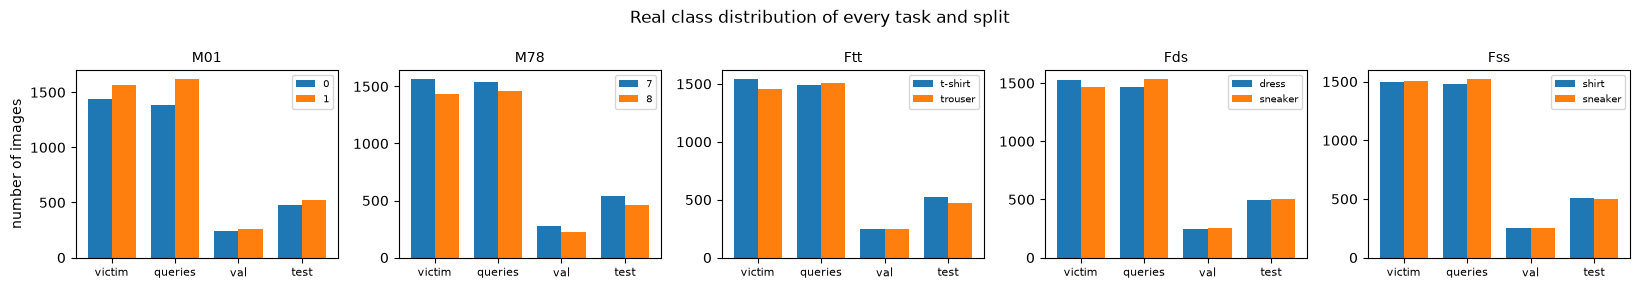

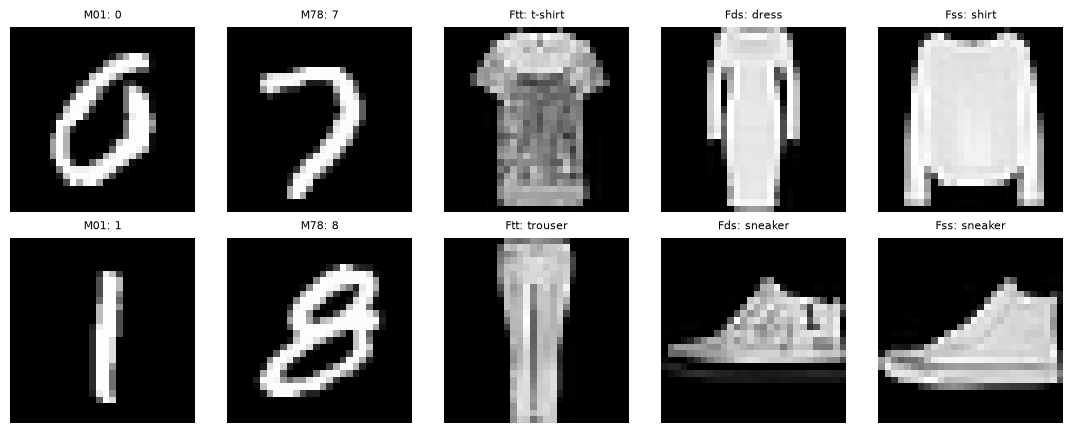

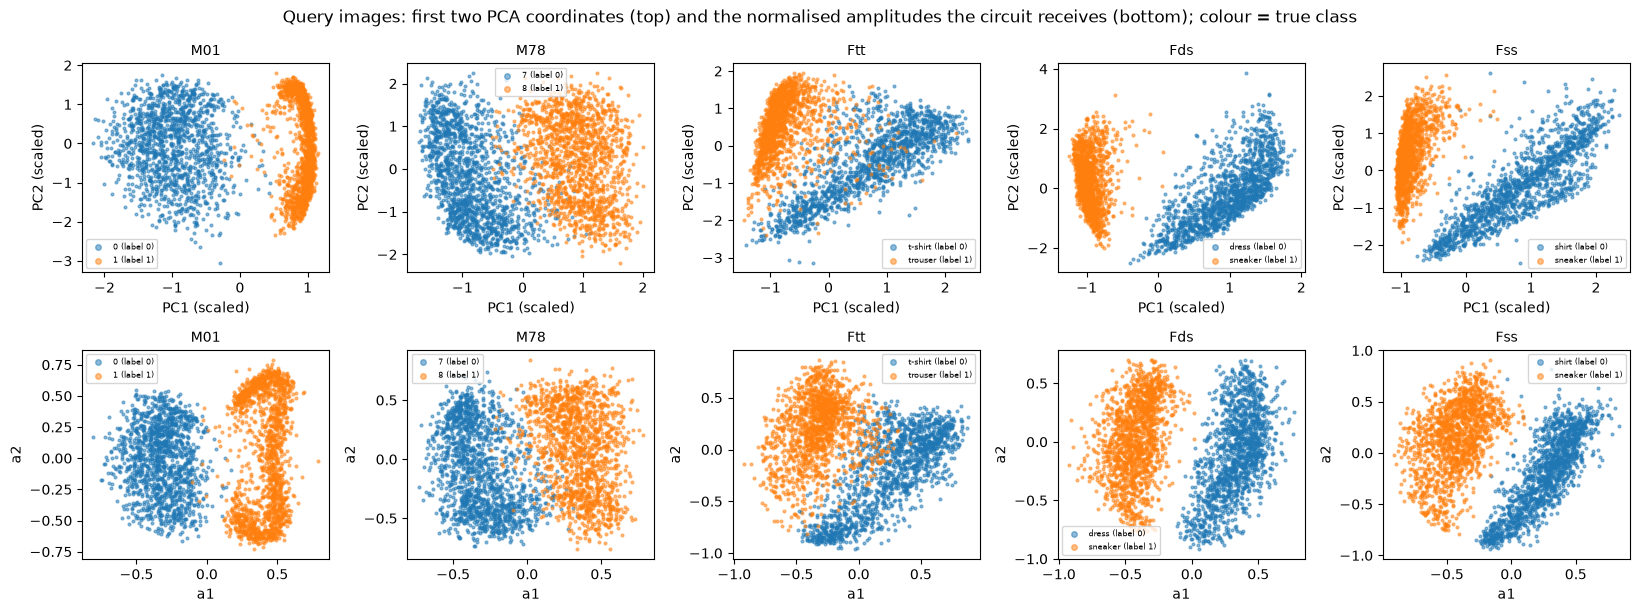

In [5]:
print("Datasets: MNIST (ylecun/mnist) and Fashion-MNIST (zalando-datasets/fashion_mnist), 28x28 grey-scale images, original label values 0..9")
rows = []
for t in TASKS:
    d = TD[t]; ds, a, b = TASK_DEF[t]
    for split, y in [("victim train", d["y_v"]), ("attacker queries", d["y_q"]), ("validation", d["y_val"]), ("test", d["y_te"])]:
        rows.append(dict(task=t, split=split, n=len(y), classes=f"0 = {class_names(t)[0]} (orig. label {a}), 1 = {class_names(t)[1]} (orig. label {b})",
                         n_class0=int((y == 0).sum()), n_class1=int((y == 1).sum())))
print(pd.DataFrame(rows).to_string(index=False))
d0 = TD[TASKS[0]]
print(f"\nshapes for {TASKS[0]}: images {d0['img_q'].shape} (uint8, 28x28) -> PCA features {d0['Z_q'].shape} -> amplitude vectors {d0['A_q'].shape} (8 PCA numbers + 8 zeros = 16 amplitudes = 4 qubits)")
print("feature names:", [f"PC{i + 1}" for i in range(N_PCA)], "(+ 8 zero-padded amplitudes a9..a16)")
print("PCA: explained variance ratio of PC1..PC8 for", TASKS[0], np.round(d0["pca"].explained_variance_ratio_, 3))

# --- class distribution (bar chart of the real classes in every split) ---
fig, ax = plt.subplots(1, len(TASKS), figsize=(3.3 * len(TASKS), 2.9), sharey=False, squeeze=False); ax = ax[0]
for i, t in enumerate(TASKS):
    d = TD[t]; splits = [("victim", d["y_v"]), ("queries", d["y_q"]), ("val", d["y_val"]), ("test", d["y_te"])]
    w = 0.38
    for k, c in enumerate([0, 1]):
        ax[i].bar(np.arange(4) + (k - 0.5) * w, [int((y == c).sum()) for _, y in splits], w, label=class_names(t)[c])
    ax[i].set_xticks(range(4)); ax[i].set_xticklabels([s for s, _ in splits], fontsize=8); ax[i].set_title(t, fontsize=10); ax[i].legend(fontsize=7)
ax[0].set_ylabel("number of images")
plt.suptitle("Real class distribution of every task and split"); plt.tight_layout(); plt.show()

# --- example images ---
fig, ax = plt.subplots(2, len(TASKS), figsize=(2.2 * len(TASKS), 4.4), squeeze=False)
for j, t in enumerate(TASKS):
    for r in (0, 1):
        k = int(np.where(TD[t]["y_te"] == r)[0][0]); ax[r, j].imshow(TD[t]["img_te"][k], cmap="gray"); ax[r, j].axis("off")
        ax[r, j].set_title(f"{t}: {class_names(t)[r]}", fontsize=8)
plt.tight_layout(); plt.show()

# --- 2-D scatter of real observations coloured by ground-truth class ---
fig, ax = plt.subplots(2, len(TASKS), figsize=(3.3 * len(TASKS), 6.2), squeeze=False)
for j, t in enumerate(TASKS):
    d = TD[t]
    for r, (Zq, ttl) in enumerate([(d["Z_q"][:, :2], "PCA coordinates (fitted on the victim's training split)"), (d["A_q"][:, :2], "amplitudes a1, a2 sent to the circuit (L2-normalised)")]):
        for c, col in [(0, "tab:blue"), (1, "tab:orange")]:
            m = d["y_q"] == c; ax[r, j].scatter(Zq[m, 0], Zq[m, 1], s=4, alpha=0.5, c=col, label=f"{class_names(t)[c]} (label {c})")
        ax[r, j].set_title(f"{t}", fontsize=10); ax[r, j].legend(fontsize=6, markerscale=2)
    ax[0, j].set_xlabel("PC1 (scaled)"); ax[0, j].set_ylabel("PC2 (scaled)"); ax[1, j].set_xlabel("a1"); ax[1, j].set_ylabel("a2")
plt.suptitle("Query images: first two PCA coordinates (top) and the normalised amplitudes the circuit receives (bottom); colour = true class"); plt.tight_layout(); plt.show()


## 2. The quantum circuits: PyTorch for training, Qiskit for the cloud

Training a quantum circuit on a classical computer needs gradients, and Qiskit's primitives are far too slow for thousands of mini-batches. So the *trainable* circuits (victim and clones) are
simulated exactly with PyTorch (state-vector arithmetic with automatic differentiation) and the *cloud* that answers the attacker's queries is simulated with Qiskit Aer. To be sure that the two
describe the same circuit, the check at the end of this section compares them numerically.

**Circuit.** `amplitude encoding -> 2 x [ RZ(a) RY(b) RZ(c) on every qubit, then CRX(theta) on (0,1), (1,2), (2,3), (3,0) ] -> <Z> on every qubit`. Each layer has 3n single-qubit-gate parameters and n two-qubit-gate (CRX) parameters,
i.e. 32 trainable parameters in total. The measurement layer turns the four `<Z_q>` into two class scores. The class `BQNN` evaluates and trains *K independent circuits at once* (a batched matrix product of
16x16 unitaries), so that all victims, all ensemble members, all co-teaching pairs and all grid points of the experiment train together.

In [6]:
# ---------- gates (PyTorch, complex128) ----------
def rot_mats(abc):
    """Fused RZ(c) RY(b) RZ(a) for every row of abc (..., 3) -> (..., 2, 2) complex."""
    a, b, c = abc[..., 0], abc[..., 1], abc[..., 2]
    cb, sb = torch.cos(b / 2), torch.sin(b / 2)
    e = lambda x: torch.polar(torch.ones_like(x), x)
    return torch.stack([torch.stack([cb * e(-(a + c) / 2), -sb * e((a - c) / 2)], -1),
                        torch.stack([sb * e((c - a) / 2),  cb * e((a + c) / 2)], -1)], -2)

def crx_mat(theta):
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    rx = torch.stack([torch.stack([c + 0j, -1j * s], -1), torch.stack([-1j * s, c + 0j], -1)], -2)
    return torch.block_diag(torch.eye(2, dtype=rx.dtype), rx)

def amp_encode(x, n):
    """Amplitude encoding: real vectors (B, 2^n) -> normalised state tensor (B,2,...,2) whose axis q+1 is qubit q
    (Qiskit little endian: basis index = sum_q b_q 2^q)."""
    x = x / (x.norm(dim=1, keepdim=True) + 1e-12)
    return x.to(torch.complex128).reshape((-1,) + (2,) * n).permute(0, *range(n, 0, -1))

def apply_1q(psi, U, q):
    return torch.movedim(torch.movedim(psi, q + 1, -1) @ U.T, -1, q + 1)

def apply_2q(psi, M, q0, q1):
    psi = torch.movedim(psi, [q0 + 1, q1 + 1], [-2, -1]); shp = psi.shape
    psi = (psi.reshape(*shp[:-2], 4) @ M.T).reshape(shp)
    return torch.movedim(psi, [-2, -1], [q0 + 1, q1 + 1])

def vqc_apply(psi, params, n):
    """Gate-by-gate version. params: (L, n, 4) = per layer and qubit: (a, b, c) of RZ RY RZ and the angle of the CRX (q -> q+1 mod n)."""
    for l in range(params.shape[0]):
        U = rot_mats(params[l, :, :3]).to(psi.dtype)
        for q in range(n): psi = apply_1q(psi, U[q], q)
        for q in range(n): psi = apply_2q(psi, crx_mat(params[l, q, 3]).to(psi.dtype), q, (q + 1) % n)
    return psi

_ZS = {}
def z_expvals(psi, n):
    """<Z_q> for every qubit from a flat or tensor state (qubit 0 = most significant bit of the flat index)."""
    if n not in _ZS:
        _ZS[n] = torch.tensor([[1 - 2 * ((k >> (n - 1 - q)) & 1) for q in range(n)] for k in range(2 ** n)], dtype=torch.float64)
    return (psi.real ** 2 + psi.imag ** 2).reshape(psi.shape[0], -1).double() @ _ZS[n]

# ---------- K small circuits at once via dense unitaries ----------
_RING = {}
def ring_constants(n):
    """Constant matrices D0, D1, D2 with CRX(theta) = D0 + cos(theta/2) D1 - i sin(theta/2) D2 for control q, target (q+1) mod n."""
    if n in _RING: return _RING[n]
    I2 = torch.eye(2, dtype=torch.complex128); P0 = torch.diag(torch.tensor([1, 0], dtype=torch.complex128))
    P1 = torch.diag(torch.tensor([0, 1], dtype=torch.complex128)); X = torch.tensor([[0, 1], [1, 0]], dtype=torch.complex128)
    def kron_all(ops):
        out = ops[0]
        for o in ops[1:]: out = torch.kron(out, o)
        return out
    D = []
    for c in range(n):
        t = (c + 1) % n
        def build(opc, opt):
            ops = [I2] * n; ops[c] = opc; ops[t] = opt
            return kron_all(ops)
        D.append(torch.stack([build(P0, I2), build(P1, I2), build(P1, X)]))
    _RING[n] = torch.stack(D)
    return _RING[n]

def vqc_unitary_b(params, n):
    """params (K, L, n, 4) -> (K, 2^n, 2^n): the unitaries of K circuits at once (qubit 0 = most significant bit)."""
    D = ring_constants(n); K = params.shape[0]; U = None
    for l in range(params.shape[1]):
        R = rot_mats(params[:, l, :, :3])                                      # (K,n,2,2)
        Kr = R[:, 0]
        for q in range(1, n):
            d = Kr.shape[-1]
            Kr = torch.einsum("kab,kcd->kacbd", Kr, R[:, q]).reshape(K, d * 2, d * 2)
        th = params[:, l, :, 3]
        coef = torch.stack([torch.ones_like(th) + 0j, torch.cos(th / 2) + 0j, -1j * torch.sin(th / 2)], -1)
        ring = torch.einsum("kqc,qcij->kqij", coef, D)
        Ul = Kr
        for q in range(n): Ul = ring[:, q] @ Ul
        U = Ul if U is None else Ul @ U
    return U

def _rev_index(n):
    return torch.tensor([int(format(j, f"0{n}b")[::-1], 2) for j in range(2 ** n)])

class BQNN(nn.Module):
    """K independent QNNs (amplitude encoding -> L VQC layers -> <Z> on every qubit), evaluated and trained together.
    Adam acts element-wise, so this is identical to training K separate models; it is just much faster in PyTorch."""
    def __init__(self, K, n, layers, seeds, init_std=None):
        """init_std=None: angles uniform in [-pi, pi] (victims); init_std=s: angles N(0, s^2), a near-identity start (clones)."""
        super().__init__()
        self.n, self.L, self.K = n, layers, K
        gen = lambda s: torch.Generator().manual_seed(int(s))
        p = [(torch.rand(layers, n, 4, generator=gen(s), dtype=torch.float64) * 2 - 1) * math.pi if init_std is None else
             torch.randn(layers, n, 4, generator=gen(s), dtype=torch.float64) * init_std for s in seeds]
        self.params = nn.Parameter(torch.stack(p)); self.rev = _rev_index(n)
    def forward(self, x):                                                      # x: (K, B, 2^n) -> (K, B, n)
        x = x / (x.norm(dim=-1, keepdim=True) + 1e-12)
        psi = torch.einsum("kbi,kji->kbj", x[..., self.rev].to(torch.complex128), vqc_unitary_b(self.params, self.n))
        return z_expvals(psi.reshape(-1, 2 ** self.n), self.n).reshape(x.shape[0], x.shape[1], self.n)

def head(z):
    """Measurement layer of victim and clones: <Z> of qubits {0,1} summed -> class-0 score, qubits {2,3} -> class-1 score."""
    return z.reshape(*z.shape[:-1], 2, -1).sum(-1)

def n_params(n, L):
    return 3 * n * L, n * L                       # (single-qubit-gate parameters, two-qubit-gate parameters)
print("trainable parameters of one 4-qubit, 2-layer QNN: 1QG %d + 2QG %d = %d" % (*n_params(4, 2), sum(n_params(4, 2))))


trainable parameters of one 4-qubit, 2-layer QNN: 1QG 24 + 2QG 8 = 32


### 2b. Check: the PyTorch circuits are the same circuits as the Qiskit ones

`var_circuit` builds the variational part of the circuit in Qiskit (RZ, RY, RZ, then CRX gates). We compare `<Z_q>` computed by Qiskit's exact `Statevector` with the PyTorch value for random parameters and random inputs,
for the dense-unitary path used in training and for the gate-by-gate path.

In [7]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, SparsePauliOp

def var_circuit(params, n=N_QUBITS):
    """Qiskit version of vqc_apply: per layer RZ(a) RY(b) RZ(c) on each qubit, then the CRX ring (q -> q+1 mod n)."""
    qc = QuantumCircuit(n)
    for l in range(params.shape[0]):
        for q in range(n):
            a, b, c = params[l, q, :3]
            qc.rz(float(a), q); qc.ry(float(b), q); qc.rz(float(c), q)
        for q in range(n):
            qc.crx(float(params[l, q, 3]), q, (q + 1) % n)
    return qc

def qiskit_z(x, params, n=N_QUBITS):
    """<Z_q> of the ideal circuit |x> -> VQC, computed by Qiskit's exact Statevector."""
    qc = QuantumCircuit(n); qc.initialize(x / np.linalg.norm(x), range(n)); qc.compose(var_circuit(params, n), inplace=True)
    sv = Statevector(qc)
    return np.array([sv.expectation_value(SparsePauliOp("I" * (n - 1 - q) + "Z" + "I" * q)).real for q in range(n)])

rg = np.random.default_rng(SEED)
x4 = torch.tensor(amp_vector(rg.normal(size=(3, N_PCA))))
bm = BQNN(1, 4, N_LAYERS, [7]); z_dense = bm(x4[None])[0].detach().numpy()
z_state = z_expvals(vqc_apply(amp_encode(x4, 4), bm.params[0], 4), 4).detach().numpy()
err_dense = max(np.abs(qiskit_z(x4[i].numpy(), bm.params[0].detach().numpy()) - z_dense[i]).max() for i in range(3))
err_state = max(np.abs(qiskit_z(x4[i].numpy(), bm.params[0].detach().numpy()) - z_state[i]).max() for i in range(3))
print(f"max |Qiskit - PyTorch| of <Z>:  dense-unitary path {err_dense:.1e} | gate-by-gate path {err_state:.1e}")
assert err_dense < 1e-8 and err_state < 1e-8
print("The PyTorch circuits (used to train and to evaluate the clones) and the Qiskit circuits (sent to the simulated cloud) agree.")


max |Qiskit - PyTorch| of <Z>:  dense-unitary path 7.5e-13 | gate-by-gate path 7.5e-13
The PyTorch circuits (used to train and to evaluate the clones) and the Qiskit circuits (sent to the simulated cloud) agree.


### 2c. Training routines

`train_single` trains many independent clones (Base, the members of an ensemble, the victims). `train_coteach` implements Fig. 5(a) and 5(c) for many pairs of clones at once: in every mini-batch each network ranks the samples by its own loss, keeps the
`(1 - f)` fraction with the smallest loss and the *peer* is updated on that selection. `vth = inf` removes the split (classical co-teaching).

In [8]:
# a clone starts close to the identity circuit (small random angles): far more stable than a uniform start in [-pi, pi]   # CHOICE
clone = lambda K, seed0: BQNN(K, N_QUBITS, N_LAYERS, [seed0 + i for i in range(K)], init_std=CLONE_INIT_STD)

def per_sample_loss(logits, y, kind):
    """logits (K,B,2) = output of the measurement layer, y (K,B,2) = queried probability vectors -> loss per sample (K,B).
    'ce'    : cross-entropy with soft labels (= negative log-likelihood for one-hot labels), the loss of classical CloudLeak / co-teaching.
    'huber' : 2-dimensional Huber loss between the clone's probability vector and the queried one (QuantumLeak). CHOICE: delta = 1."""
    if kind == "ce":
        return -(y * F.log_softmax(logits, -1)).sum(-1)
    return F.huber_loss(F.softmax(logits, -1), y, reduction="none", delta=1.0).sum(-1)

def train_single(model, ct, Xs, Ys, slot_idx, epochs, bs, lr, wd, seed, loss="ce", hist=None):
    """Train K independent clones. Clone k works on task ct[k] and uses the queried instances slot_idx[k] (K, n) of that task
    (identity for Base, a bootstrap sample for the QuantumLeak members). Adam, one random mini-batch order per clone and epoch."""
    torch.manual_seed(int(seed))
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    K, n = slot_idx.shape; tk = ct[:, None]
    for ep in range(epochs):
        order = torch.gather(slot_idx, 1, torch.argsort(torch.rand(K, n), dim=1)); tot = 0.0; nb = 0
        for s in range(0, n, bs):
            idx = order[:, s:s + bs]
            l = per_sample_loss(head(model(Xs[tk, idx])), Ys[tk, idx], loss).mean(1).sum()
            opt.zero_grad(); l.backward(); opt.step(); tot += l.item(); nb += 1
        if hist is not None: hist.append(tot / nb / K)
    return model

class MaskedAdam:
    """Adam (L2 weight decay, as torch.optim.Adam) for stacked parameters of shape (K, ...) in which only the rows flagged `active` are updated.
    The K pairs of a co-teaching run have different numbers of mini-batches (the sizes of D_r and D_v differ with Vth). A row that has run out of
    batches must not move: torch's Adam would keep applying momentum and the weight-decay gradient to it (Adam normalises even a tiny gradient to a
    full step) and slowly destroy that clone. Each row has its own step counter for the bias correction."""
    def __init__(self, params, lr, weight_decay, betas=(0.9, 0.999), eps=1e-8):
        self.p = list(params); self.lr, self.wd, self.b1, self.b2, self.eps = lr, weight_decay, betas[0], betas[1], eps
        self.m = [torch.zeros_like(p) for p in self.p]; self.v = [torch.zeros_like(p) for p in self.p]; self.t = [torch.zeros(p.shape[0], dtype=torch.float64) for p in self.p]
    def zero_grad(self):
        for p in self.p: p.grad = None
    @torch.no_grad()
    def step(self, active):
        a = active.double()
        for i, p in enumerate(self.p):
            sh = (-1,) + (1,) * (p.dim() - 1); am = a.reshape(sh) > 0
            g = p.grad + self.wd * p
            self.t[i] += a
            self.m[i] = torch.where(am, self.b1 * self.m[i] + (1 - self.b1) * g, self.m[i])
            self.v[i] = torch.where(am, self.b2 * self.v[i] + (1 - self.b2) * g * g, self.v[i])
            t = self.t[i].clamp(min=1).reshape(sh); bc1 = 1 - self.b1 ** t; bc2 = 1 - self.b2 ** t
            p -= a.reshape(sh) * (self.lr / bc1) * self.m[i] / (self.v[i].sqrt() / bc2.sqrt() + self.eps)

def train_coteach(mA, mB, ct, Xs, Ys, VAR, vth, f1, f2, epochs, bs, lr, wd, seed, loss="ce", ramp=0, slot_idx=None, hist=None):
    """Co-teaching of K pairs of QNNs (Q1 = mA[k], Q2 = mB[k]); paper Fig. 5(c) and, with two groups, Fig. 5(a).
    Every instance has a normalised label-variation score VAR (Fig. 5(b)); instances with VAR <= vth[k] form the robust set D_r, the rest
    the vulnerable set D_v. Each epoch shuffles D_r and D_v, runs SCOT on D_r with forget rate f1[k] and then SCOT on D_v with f2[k].
    SCOT: for every mini-batch both networks rank the samples by their own loss, each keeps the (1 - f) fraction with the smallest loss,
    and the network is updated on the samples chosen by its PEER. vth = inf gives one group = classical co-teaching with forget rate f1.
    ramp > 0 ramps the forget rate linearly from 0 to its value over `ramp` epochs (classical co-teaching, Han et al. 2018)."""
    torch.manual_seed(int(seed))
    opt = MaskedAdam(list(mA.parameters()) + list(mB.parameters()), lr, wd)
    K = mA.K; N = Xs.shape[1]; tk = ct[:, None]
    base = slot_idx if slot_idx is not None else torch.arange(N)[None, :].expand(K, N)
    n = base.shape[1]
    robust = VAR[tk, base] <= torch.as_tensor(vth, dtype=torch.float64)[:, None]
    f1 = torch.as_tensor(f1, dtype=torch.float64); f2 = torch.as_tensor(f2, dtype=torch.float64)
    for ep in range(epochs):
        rf = min(1.0, ep / ramp) if ramp > 0 else 1.0
        tot = 0.0; nb = 0
        for grp, f in ((robust, f1 * rf), (~robust, f2 * rf)):
            order = torch.gather(base, 1, torch.argsort(torch.rand(K, n) + (~grp).double() * 2.0, dim=1))   # members of the group first, random order
            cnt = grp.sum(1)
            for s in range(0, int(cnt.max().item()), bs):
                pos = torch.arange(s, s + bs)[None, :]; valid = pos < cnt[:, None]               # (K,B)
                idx = order[:, s:s + bs]
                if idx.shape[1] < bs: valid = valid[:, :idx.shape[1]]
                xb, yb = Xs[tk, idx], Ys[tk, idx]
                lA = per_sample_loss(head(mA(xb)), yb, loss); lB = per_sample_loss(head(mB(xb)), yb, loss)     # (K,B)
                nv = valid.sum(1); keep = torch.where(nv > 0, torch.ceil((1 - f) * nv - 1e-9).clamp(min=1), torch.zeros_like(f))
                def chosen(l):                                                                   # the (1-f) fraction with the smallest loss
                    rank = torch.argsort(torch.argsort(l.detach().masked_fill(~valid, float("inf")), 1), 1)
                    return ((rank < keep[:, None]) & valid).double()
                selA, selB = chosen(lA), chosen(lB)
                tA = (lA * selB).sum(1) / selB.sum(1).clamp(min=1)                               # Q1 learns from the samples Q2 trusts
                tB = (lB * selA).sum(1) / selA.sum(1).clamp(min=1)                               # Q2 learns from the samples Q1 trusts
                l = tA.sum() + tB.sum()
                opt.zero_grad(); l.backward(); opt.step(nv > 0); tot += l.item(); nb += 1          # pairs without a sample in this step are not touched
        if hist is not None: hist.append(tot / max(nb, 1) / K / 2)
    return mA, mB

def predict_logits(model, ct, Xev):
    """Output of the measurement layer of clone k on the evaluation set of its task: Xev (T,Nev,16) -> (K,Nev,2)."""
    with torch.no_grad(): return head(model(Xev[ct]))


## 3. The victim QNNs (trained noise-free by their owner)

Each task gets its own victim: 4 qubits, amplitude encoding of the 8 PCA numbers, two VQC layers, measurement layer, softmax. Training follows the paper: negative log-likelihood, Adam with learning rate 5e-3 and weight decay 1e-4,
batch size 32, 30 epochs. All victims train in one batched run. The accuracy is that of an ideal (noise-free) simulator, the paper's "Ideal" bar.

trained 5 victims in 100 s (epochs=30, batch=32)
                                              M01   M78   Ftt   Fds   Fss
ideal (noise-free) victim test accuracy (%)  98.3  87.3  93.8  96.1  96.4


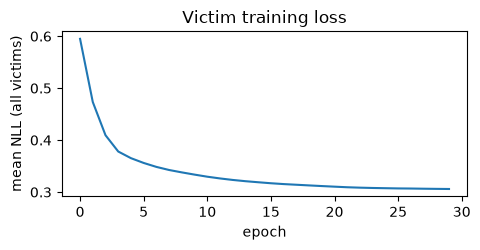

In [9]:
t0 = time.time()
TIDX = {t: i for i, t in enumerate(TASKS)}
Xv_all = torch.tensor(np.stack([TD[t]["A_v"] for t in TASKS])); Yv_all = F.one_hot(torch.tensor(np.stack([TD[t]["y_v"] for t in TASKS])), 2).double()
Xte_all = torch.tensor(np.stack([TD[t]["A_te"] for t in TASKS])); yte_all = torch.tensor(np.stack([TD[t]["y_te"] for t in TASKS]))
Xval_all = torch.tensor(np.stack([TD[t]["A_val"] for t in TASKS])); yval_all = torch.tensor(np.stack([TD[t]["y_val"] for t in TASKS]))
ct_task = torch.arange(len(TASKS))                                       # clone k <-> task k

victims = BQNN(len(TASKS), N_QUBITS, N_LAYERS, [SEED + 7 * i for i in range(len(TASKS))])
vhist = []
train_single(victims, ct_task, Xv_all, Yv_all, torch.arange(Xv_all.shape[1])[None, :].expand(len(TASKS), -1).contiguous(),
             VICTIM_EPOCHS, VICTIM_BS, VICTIM_LR, VICTIM_WD, SEED, loss="ce", hist=vhist)       # NLL, Adam 5e-3, wd 1e-4, batch 32 (paper)
ideal_logits = predict_logits(victims, ct_task, Xte_all)
VIC = {}
for i, t in enumerate(TASKS):
    pred = ideal_logits[i].argmax(1)
    VIC[t] = dict(params=victims.params[i].detach().numpy().copy(), ideal_pred=pred, ideal_acc=(pred == yte_all[i]).double().mean().item())
print(f"trained {len(TASKS)} victims in {time.time() - t0:.0f} s (epochs={VICTIM_EPOCHS}, batch={VICTIM_BS})")
print(pd.Series({t: round(VIC[t]["ideal_acc"] * 100, 1) for t in TASKS}, name="ideal (noise-free) victim test accuracy (%)").to_frame().T.to_string())
plt.figure(figsize=(5, 2.6)); plt.plot(vhist); plt.xlabel("epoch"); plt.ylabel("mean NLL (all victims)"); plt.title("Victim training loss"); plt.tight_layout(); plt.show()


## 4. The simulated QNN-as-a-Service: a noisy cloud whose noise drifts during the day

The paper queries IBM Quebec at five times of the day and notes that gate errors change from hour to hour (Table 1). We have no hardware, so the cloud is a **Qiskit Aer density-matrix simulation** with a noise model whose parameters
change smoothly over 24 hours (`DeviceDrift`: a few sinusoids with random periods and phases per noise component):

* depolarising error on RY (single-qubit) and CX (two-qubit) gates; RZ is a virtual gate on IBM machines and is noise free,
* amplitude damping (T1-like) after the gates and after state preparation, which pushes qubits towards |0>,
* asymmetric read-out error `P(1|0) < P(0|1)`,
* a small coherent RY over-rotation per qubit that wanders over the day (the paper cites control imperfections and crosstalk).

State preparation is ideal (`set_statevector`), followed by one noisy `id` gate per qubit that represents the deep circuit into which amplitude encoding is compiled on real hardware.
The service returns, as in the paper, the raw output estimated from `SHOTS` measurement shots. A single global scale **`NOISE_LEVEL`** multiplies all noise strengths; it is the only fitted number of the notebook (Section 4b).
Every component has a static part (for example a fixed over-rotation per qubit, the same all day: such errors make the same images wrong in every round) and a time-dependent part of relative size `DRIFT`.

**Speed trick, and why it is exact.** The noisy circuit is a linear map of the density matrix, hence for a real input vector `x` the probability of outcome `k` is `p_k(x) = x^T S_k x` for 16 fixed symmetric matrices. They are read off from 136 Aer runs per
(task, round) with the inputs |i> and (|i> + |j>)/sqrt2. Every query of that round is then a matrix product, and the shots are sampled from `p`. The last lines of the next cell compare this with direct Aer runs that include measurement and read-out error.

In [10]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (NoiseModel, depolarizing_error, ReadoutError, amplitude_damping_error, coherent_unitary_error)
from qiskit_aer.library import SetStatevector, SaveProbabilities  # noqa: F401  (registers QuantumCircuit.set_statevector / save_probabilities)
from qiskit.quantum_info import Operator
from qiskit.circuit.library import RYGate

CLOUD_BASIS = ["rx", "ry", "rz", "cx", "id"]
SGN = np.array([[1 - 2 * ((k >> q) & 1) for q in range(N_QUBITS)] for k in range(2 ** N_QUBITS)])     # eigenvalue of Z_q on basis state k

class DeviceDrift:
    """One simulated day of a device. Besides a *static* part (a fixed coherent error per qubit, the same all day) every noise
    component drifts smoothly: a few sinusoids (periods 2 h ... 24 h, random phases). value(h, k) is roughly in [-1, 1].
    One seed = one simulated day (different static offsets and different drift)."""
    def __init__(self, seed, n_series=16, n_waves=4):
        g = np.random.default_rng(seed)
        self.per = g.uniform(2.0, 24.0, (n_series, n_waves)); self.ph = g.uniform(0, 2 * np.pi, (n_series, n_waves))
        self.amp = g.uniform(0.3, 1.0, (n_series, n_waves)); self.amp /= self.amp.sum(1, keepdims=True)
        self.static = g.uniform(0.5, 1.0, 8) * g.choice([-1.0, 1.0], 8)
    def value(self, h, k):
        return float((self.amp[k] * np.sin(2 * np.pi * h / self.per[k] + self.ph[k])).sum())

def noise_at(h, day, level, n=N_QUBITS):
    """Noise parameters of the simulated device at hour h of `day`. CHOICE: base values are typical NISQ orders of magnitude
    times `level`; every component drifts with time by +-DRIFT (relative)."""
    d = lambda k: day.value(h, k)
    s = 1 + DRIFT * d(0)                                                     # overall multiplier of gate noise
    return dict(p1=0.002 * level * s, p2=0.02 * level * s, gamma=0.01 * level * s,
                p_ro01=0.02 * level * (1 + DRIFT * d(1)), p_ro10=0.04 * level * (1 + DRIFT * d(2)), p_enc=0.03 * level * s,
                delta=[0.12 * level * (day.static[q] + DRIFT * d(3 + q)) for q in range(n)])   # coherent RY over-rotation per qubit (rad)

def make_noise_model(nz, n=N_QUBITS, readout=True):
    nm = NoiseModel(basis_gates=CLOUD_BASIS + ["set_statevector"])
    ad1 = amplitude_damping_error(min(1.0, nz["gamma"] * 0.5))
    for q in range(n):
        coh = coherent_unitary_error(Operator(RYGate(nz["delta"][q])))
        nm.add_quantum_error(coh.compose(depolarizing_error(nz["p1"], 1)).compose(ad1), ["ry"], [q])
        nm.add_quantum_error(depolarizing_error(nz["p1"], 1), ["rx"], [q])
    ad2 = amplitude_damping_error(min(1.0, nz["gamma"]))
    nm.add_all_qubit_quantum_error(depolarizing_error(nz["p2"], 2).compose(ad2.tensor(ad2)), ["cx"])
    nm.add_all_qubit_quantum_error(depolarizing_error(nz["p_enc"], 1).compose(amplitude_damping_error(min(1.0, nz["gamma"] * 2))), ["id"])
    if readout:
        nm.add_all_qubit_readout_error(ReadoutError([[1 - nz["p_ro01"], nz["p_ro01"]], [nz["p_ro10"], 1 - nz["p_ro10"]]]))
    return nm

def cloud_circuit(amp, var_t, n=N_QUBITS, measure=True, save=False):
    """The circuit the QNN-as-a-Service executes for one query: amplitude encoding (one noisy `id` per qubit stands for the compiled
    encoding circuit), the victim's VQC, and the measurement."""
    qc = QuantumCircuit(n, n if measure else 0); qc.set_statevector(amp)
    for q in range(n): qc.id(q)
    qc.compose(var_t, inplace=True)
    if measure: qc.measure(range(n), range(n))
    if save: qc.save_probabilities()
    return qc

def fit_cloud_channel(params, nz, n=N_QUBITS):
    """Qiskit-Aer density-matrix simulation of the noisy cloud, condensed into 16 symmetric 16x16 matrices S_k.
    For a real input vector x (unit norm) the probability of measuring basis state k is exactly p_k(x) = x^T S_k x, because the noisy
    circuit is a linear map of the density matrix |x><x|. S_k is read off from the 16 basis states |i> and the 120 states (|i>+|j>)/sqrt2
    (136 Aer runs); the classical read-out error is applied afterwards. This gives the exact noisy output distribution of any input
    in one matrix product instead of one Aer run per query."""
    dim = 2 ** n; var_t = transpile(var_circuit(params, n), basis_gates=CLOUD_BASIS, optimization_level=0)
    backend = AerSimulator(method="density_matrix", noise_model=make_noise_model(nz, n, readout=False))
    pairs = [(i, j) for i in range(dim) for j in range(i + 1, dim)]
    vecs = []
    for i in range(dim): v = np.zeros(dim, complex); v[i] = 1; vecs.append(v)
    for i, j in pairs: v = np.zeros(dim, complex); v[i] = v[j] = 1 / np.sqrt(2); vecs.append(v)
    res = backend.run([cloud_circuit(v, var_t, n, measure=False, save=True) for v in vecs]).result()
    P = np.array([res.data(k)["probabilities"] for k in range(len(vecs))])                      # (136, 16): outcome distribution before read-out error
    C = np.array([[1 - nz["p_ro01"], nz["p_ro10"]], [nz["p_ro01"], 1 - nz["p_ro10"]]])           # confusion matrix of one qubit (rows: measured, columns: true)
    R = C
    for _ in range(n - 1): R = np.kron(R, C)
    P = P @ R.T                                                                                  # apply the read-out error
    S = np.zeros((dim, dim, dim))                                                                # S[i, j, k]
    for i in range(dim): S[i, i] = P[i]
    for m, (i, j) in enumerate(pairs):
        S[i, j] = S[j, i] = P[dim + m] - 0.5 * (P[i] + P[j])
    return S.transpose(2, 0, 1)                                                                  # (k, i, j)

def cloud_answer(amps, S, shots, g):
    """What the service returns for a batch of queries: the raw output <Z_q> estimated from `shots` measurement shots, shape (N, 4),
    together with the exact noisy outcome distribution (not visible to an attacker, used for checks only)."""
    x = amps / (np.linalg.norm(amps, axis=1, keepdims=True) + 1e-12)
    p = np.einsum("ni,kij,nj->nk", x, S, x); p = np.clip(p, 0, None); p /= p.sum(1, keepdims=True)
    counts = g.multinomial(shots, p)
    return counts @ SGN / shots, p @ SGN

def to_probs(raw):
    """Raw <Z> output of the service -> probability vector over the two classes (softmax of the measurement layer, as the QNN does)."""
    return F.softmax(head(torch.tensor(raw)), -1).numpy()

# ---- check 1: the condensed channel reproduces a direct Aer run with measurement and read-out error ----
day_chk = DeviceDrift(0); nz_chk = noise_at(6.0, day_chk, 2.0)
par_chk = VIC[TASKS[0]]["params"]; S_chk = fit_cloud_channel(par_chk, nz_chk)
imgs_chk = TD[TASKS[0]]["A_te"][:12]
var_chk = transpile(var_circuit(par_chk), basis_gates=CLOUD_BASIS, optimization_level=0)
direct = AerSimulator(method="density_matrix", noise_model=make_noise_model(nz_chk))
res_chk = direct.run([cloud_circuit(v.astype(complex), var_chk) for v in imgs_chk], shots=40000, seed_simulator=SEED).result()
z_direct = np.array([[sum(cnt * SGN[int(key, 2), q] for key, cnt in res_chk.get_counts(i).items()) / 40000 for q in range(N_QUBITS)] for i in range(len(imgs_chk))])
_, z_exact = cloud_answer(imgs_chk, S_chk, 1000, np.random.default_rng(0))
print(f"max |<Z> direct Aer (40000 shots) - <Z> from the condensed channel| over 12 images and 4 qubits: {np.abs(z_direct - z_exact).max():.4f}  (shot noise ~0.005)")
assert np.abs(z_direct - z_exact).max() < 0.03


max |<Z> direct Aer (40000 shots) - <Z> from the condensed channel| over 12 images and 4 qubits: 0.0094  (shot noise ~0.005)


### 4a. Querying the cloud: helper functions

`query_task` sends a task's query images in `M` rounds at the hours `24 k / M` of a simulated day (one fit of the cloud channel per round, Section 4) and returns the probability vectors that the service answers;
`variance_score` is the label variation of Fig. 5(b); `build_bundle` stacks the queried instances of several tasks for the batched trainers.

In [11]:
def query_task(task, day, level, qseed, n_query=None, rounds=M_ROUNDS):
    """Multi-round query (paper Sec. 4.1): the same unlabelled images are sent in `rounds` rounds, at the hours 24 k / rounds.
    Returns P with shape (rounds, N, 2) = the probability vectors the service returned, and the accuracy of the noisy victim on the
    test set in each round (a diagnostic the attacker cannot see)."""
    d = TD[task]; par = VIC[task]["params"]; n_query = n_query or len(d["A_q"])
    P = np.zeros((rounds, n_query, 2)); acc = []; g = np.random.default_rng(qseed)
    for k in range(rounds):
        S = fit_cloud_channel(par, noise_at(24.0 * k / rounds, day, level))
        raw, _ = cloud_answer(d["A_q"][:n_query], S, SHOTS, g)
        P[k] = to_probs(raw)
        rawt, _ = cloud_answer(d["A_te"], S, SHOTS, g)
        acc.append(float((head(torch.tensor(rawt)).argmax(1).numpy() == d["y_te"]).mean()))
    return P, np.array(acc)

def variance_score(P):
    """Paper Fig. 5(b): label variation of every queried image across the M rounds. For image i and class j the M probabilities
    P_ij have a variance; var_i is its mean over the classes, divided by the largest value in the data set so that var in [0, 1]."""
    v = P.var(0).mean(-1)
    return v / (v.max() + 1e-12)

def build_bundle(Ps, tasks):
    """Stack the queried data of several tasks for the batched trainers. An instance is one (image, round) pair with that round's
    probability vector as label; instance index = round * N + image."""
    Xs = torch.tensor(np.stack([np.tile(TD[t]["A_q"][:Ps[t].shape[1]], (Ps[t].shape[0], 1)) for t in tasks]))
    Ys = torch.tensor(np.stack([Ps[t].reshape(-1, 2) for t in tasks]))
    VAR = torch.tensor(np.stack([np.tile(variance_score(Ps[t]), Ps[t].shape[0]) for t in tasks]))
    return Xs, Ys, VAR


### 4b. Fitting the one free number: the noise scale

The paper does not give the noise level of IBM Quebec, but its preliminary study reports the accuracy of the classical-extraction clone ("Base") with 3000 images and 5 rounds on MNIST: **86.7 %** (Fig. 2; the figure labels are read from the extracted text:
98.8 ideal, then 86.7, 87.5, 89.3, 88.3 for Base, QLeak, CoT, CoT-E, consistent with the text of Observations 1 and 2).
We therefore choose, once, the `NOISE_LEVEL` for which the Base clone of M01 on a separate *calibration day* is closest to 86.7 %. **This makes the Base value of claim C2 a fit and not a test**; everything else (QLeak, CoT, CoT-E, the other tasks,
split co-teaching) is a prediction of the fitted simulator.

  level 2.0: queried M01 [7 s]


  level 2.5: queried M01 [14 s]


  level 2.75: queried M01 [22 s]


  level 3.0: queried M01 [31 s]


  level 3.5: queried M01 [39 s]


             noisy victim acc over the day (%)  spread over the day (max-min, points)  stolen-label accuracy (%)  Base clone acc (%)
NOISE_LEVEL                                                                                                                         
2.00                                      95.1                                    2.1                       94.1                94.9
2.50                                      92.5                                    4.0                       90.9                91.4
2.75                                      90.3                                    6.2                       88.6                91.7
3.00                                      88.0                                    6.7                       86.3                86.9
3.50                                      80.7                                   11.8                       79.0                84.5

NOISE_LEVEL = 3.0: the Base clone of M01 is closest to the paper's 8

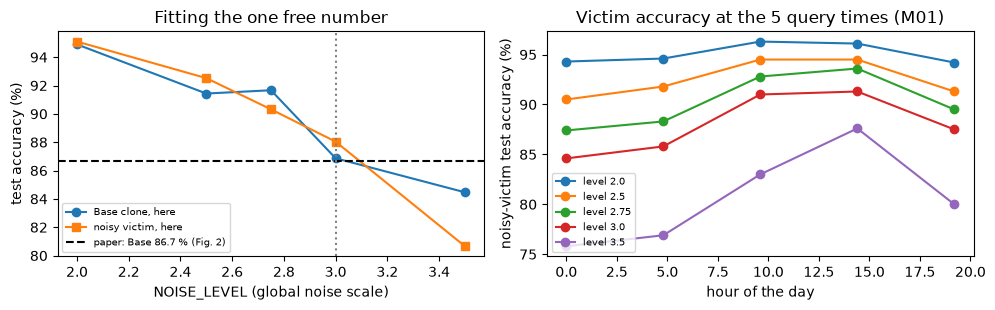

In [12]:
t0 = time.time()
day_cal = DeviceDrift(900)                           # a calibration day; the experiments below use other simulated days
cal_P, cal_vacc = {}, {}
for lev in CAL_LEVELS:
    cal_P[lev], cal_vacc[lev] = query_task("M01", day_cal, lev, 900)
    print(f"  level {lev}: queried M01 [{time.time() - t0:.0f} s]", flush=True)
L = len(CAL_LEVELS)
Xc = torch.tensor(np.tile(TD["M01"]["A_q"], (M_ROUNDS, 1)))[None].expand(L, -1, -1).contiguous()
Yc = torch.tensor(np.stack([cal_P[l].reshape(-1, 2) for l in CAL_LEVELS]))
RC = 3                                              # restarts of the Base clone per level (a single training run is too noisy to fit a number)
ctc = torch.arange(L).repeat_interleave(RC); base_cal = clone(L * RC, SEED + 31)
nI = Xc.shape[1]
train_single(base_cal, ctc, Xc, Yc, torch.arange(nI)[None, :].expand(L * RC, -1).contiguous(), CLONE_EPOCHS, CLONE_BS, CLONE_LR, CLONE_WD, SEED, loss="ce")
Xev = torch.tensor(TD["M01"]["A_te"])[None].expand(L, -1, -1).contiguous()
cal_base_acc = ((predict_logits(base_cal, ctc, Xev).argmax(-1) == torch.tensor(TD["M01"]["y_te"])[None]).double().mean(1).numpy() * 100).reshape(L, RC).mean(1)
cal_df = pd.DataFrame({"noisy victim acc over the day (%)": [cal_vacc[l].mean() * 100 for l in CAL_LEVELS],
                       "spread over the day (max-min, points)": [(cal_vacc[l].max() - cal_vacc[l].min()) * 100 for l in CAL_LEVELS],
                       "stolen-label accuracy (%)": [100 * (cal_P[l].argmax(-1) == TD["M01"]["y_q"][None]).mean() for l in CAL_LEVELS],
                       "Base clone acc (%)": cal_base_acc}, index=pd.Index(CAL_LEVELS, name="NOISE_LEVEL"))
print(cal_df.round(1).to_string())
NOISE_LEVEL = float(min(CAL_LEVELS, key=lambda l: abs(cal_df.loc[l, "Base clone acc (%)"] - TARGET_BASE_ACC_M01)))     # CHOICE: the single fitted number
print(f"\nNOISE_LEVEL = {NOISE_LEVEL}: the Base clone of M01 is closest to the paper's {TARGET_BASE_ACC_M01} % (Fig. 2)   [{time.time() - t0:.0f} s]")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(CAL_LEVELS, cal_df["Base clone acc (%)"], "o-", label="Base clone, here"); ax[0].plot(CAL_LEVELS, cal_df["noisy victim acc over the day (%)"], "s-", label="noisy victim, here")
ax[0].axhline(TARGET_BASE_ACC_M01, color="k", ls="--", label="paper: Base 86.7 % (Fig. 2)"); ax[0].axvline(NOISE_LEVEL, color="grey", ls=":")
ax[0].set_xlabel("NOISE_LEVEL (global noise scale)"); ax[0].set_ylabel("test accuracy (%)"); ax[0].legend(fontsize=7); ax[0].set_title("Fitting the one free number")
for l in CAL_LEVELS: ax[1].plot([24.0 * k / M_ROUNDS for k in range(M_ROUNDS)], cal_vacc[l] * 100, "o-", label=f"level {l}")
ax[1].set_xlabel("hour of the day"); ax[1].set_ylabel("noisy-victim test accuracy (%)"); ax[1].set_title("Victim accuracy at the 5 query times (M01)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()


## 5. Multi-round query and the queried-data split (paper Sec. 4.1, Fig. 5b)

For `N` images sent in `M = 5` rounds, round `m` returns a probability vector `P_i^m` for every image (class probabilities = softmax of the measurement layer). The variation `var(d_i)` of the 5 vectors, normalised to [0, 1], tells how much the
answers of this image fluctuate during the day. The threshold `Vth` splits the images into the robust set `D_r` (var <= Vth) and the noise-vulnerable set `D_v`.

The cell after the queries measures the quality of what the cloud returns (on a fresh simulated day for every seed) and checks the premise of the method: **are the labels of the vulnerable images really worse?**
"Wrong" means that the label of a round differs from the label of the noise-free victim (the attacker never sees this; it is only used for the analysis).

In [13]:
t0 = time.time()
QUERIES = {}
# the noise-free victim's answer for every query image: the attacker never sees it, we use it to measure how wrong the cloud labels are
Xq_all = torch.tensor(np.stack([TD[t]["A_q"] for t in TASKS]))
IDEAL_Q = predict_logits(victims, ct_task, Xq_all).argmax(-1).numpy()                 # (T, N_QUERY)
for seed in SEEDS:
    day = DeviceDrift(2000 + seed)                                                   # a fresh simulated day per seed (not the calibration day)
    Ps, vacc = {}, {}
    for ti, t in enumerate(TASKS):
        Ps[t], vacc[t] = query_task(t, day, NOISE_LEVEL, seed * 1000 + ti)
    QUERIES[seed] = dict(P=Ps, vacc=vacc, bundle=build_bundle(Ps, TASKS), day=day)
    print(f"seed {seed}: queried {len(TASKS)} tasks x {N_QUERY} images x {M_ROUNDS} rounds = {len(TASKS) * N_QUERY * M_ROUNDS} labels   [{time.time() - t0:.0f} s]", flush=True)

sd0 = SEEDS[0]
qrows = []
for ti, t in enumerate(TASKS):
    P = QUERIES[sd0]["P"][t]; lab = P.argmax(-1)                                      # (M, N) label of every round
    qrows.append({"task": t, "ideal victim acc (%)": 100 * VIC[t]["ideal_acc"],
                  "noisy victim acc over the day (%)": 100 * QUERIES[sd0]["vacc"][t].mean(),
                  "min / max over the 5 times": f"{100 * QUERIES[sd0]['vacc'][t].min():.1f} / {100 * QUERIES[sd0]['vacc'][t].max():.1f}",
                  "stolen labels = true labels (%)": 100 * (lab == TD[t]["y_q"][None]).mean(),
                  "stolen labels = ideal victim (%)": 100 * (lab == IDEAL_Q[ti][None]).mean(),
                  "images whose label changes between rounds (%)": 100 * (lab != lab[0:1]).any(0).mean()})
print(f"\nSeed {sd0}: quality of what the simulated cloud returns")
print(pd.DataFrame(qrows).set_index("task").round(1).to_string())


seed 42: queried 5 tasks x 3000 images x 5 rounds = 75000 labels   [42 s]


seed 43: queried 5 tasks x 3000 images x 5 rounds = 75000 labels   [82 s]



Seed 42: quality of what the simulated cloud returns
      ideal victim acc (%)  noisy victim acc over the day (%) min / max over the 5 times  stolen labels = true labels (%)  stolen labels = ideal victim (%)  images whose label changes between rounds (%)
task                                                                                                                                                                                                      
M01                   98.3                               82.7                76.5 / 88.7                             82.2                              81.9                                           26.2
M78                   87.3                               66.1                62.3 / 75.1                             64.1                              66.3                                           50.7
Ftt                   93.8                               73.0                69.9 / 76.7                             73.6             

Share of the data in the robust set D_r and wrong-label rate inside D_r and D_v (seed 42); 'wrong' = differs from the noise-free victim's label


     in D_r (%)                         wrong labels in D_r (%)                         wrong labels in D_v (%)                        
Vth        0.05  0.10  0.15  0.20  0.25                    0.05  0.10  0.15  0.20  0.25                    0.05  0.10  0.15  0.20  0.25
task                                                                                                                                   
Fds        16.4  41.8  62.9  76.8  86.0                    21.9  21.7  21.1  20.9  20.7                    19.7  18.9  18.4  17.3  16.2
Fss         8.8  26.4  43.0  57.4  69.7                    13.0  12.9  13.4  13.6  13.2                    12.7  12.7  12.3  11.7  11.7
Ftt        15.2  38.5  57.2  72.1  82.9                    28.5  28.6  27.9  28.1  27.9                    26.8  26.1  25.8  24.3  22.8
M01        11.6  31.0  50.6  66.3  77.5                    17.8  18.7  18.5  18.2  18.4                    18.1  17.8  17.6  17.8  16.9
M78         9.7  28.6  46.7  62.4  74.2         

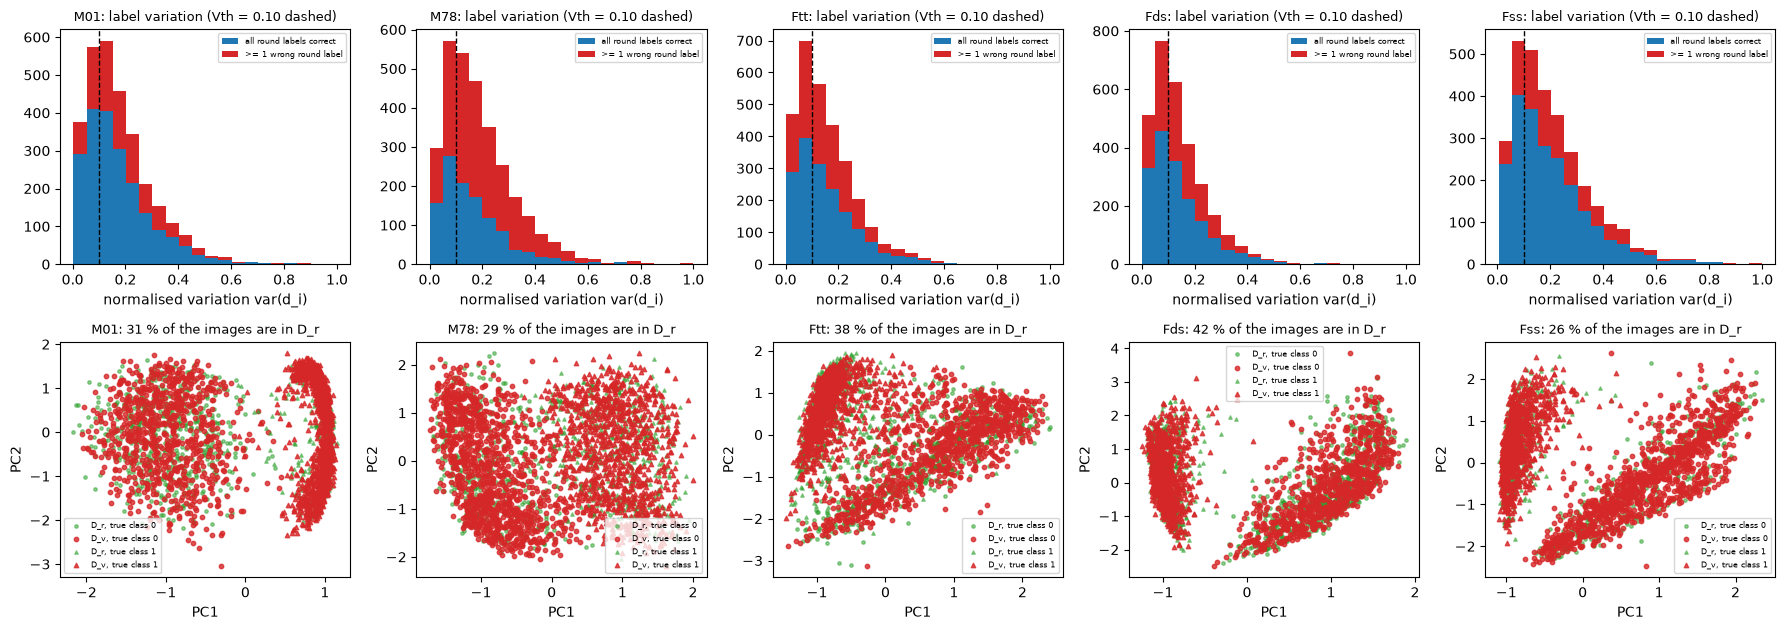


Simulated analogue of Table 1 (paper, IBM Quebec: 1QG 31.2 %, 2QG 10.3 %)
 simulated day           quantity    06:00    12:00    18:00    24:00  delta (%)
             0 1-qubit gate error 7.48e-03 4.47e-03 6.44e-03 6.54e-03       67.4
             0 2-qubit gate error 7.48e-02 4.47e-02 6.44e-02 6.54e-02       67.4
             1 1-qubit gate error 7.25e-03 3.76e-03 5.63e-03 5.10e-03       92.7
             1 2-qubit gate error 7.25e-02 3.76e-02 5.63e-02 5.10e-02       92.7
             2 1-qubit gate error 5.66e-03 6.60e-03 5.42e-03 6.01e-03       21.8
             2 2-qubit gate error 5.66e-02 6.60e-02 5.42e-02 6.01e-02       21.8


In [14]:
VTHS_SHOW = [0.05, 0.10, 0.15, 0.20, 0.25]
rows, auc_rows = [], []
for ti, t in enumerate(TASKS):
    P = QUERIES[sd0]["P"][t]; v = variance_score(P)
    err = P.argmax(-1) != IDEAL_Q[ti][None]                                     # (M, N): the label of this round differs from the noise-free victim
    for vth in VTHS_SHOW:
        rob = v <= vth
        rows.append(dict(task=t, Vth=vth, **{"in D_r (%)": 100 * rob.mean(),
                         "wrong labels in D_r (%)": 100 * err[:, rob].mean() if rob.any() else np.nan,
                         "wrong labels in D_v (%)": 100 * err[:, ~rob].mean() if (~rob).any() else np.nan}))
    anyerr = err.any(0)
    auc_rows.append(dict(task=t, **{"images with >=1 wrong round label (%)": 100 * anyerr.mean(),
                                    "AUROC(variance -> has a wrong label)": roc_auc_score(anyerr, v) if 0 < anyerr.sum() < len(v) else np.nan}))
split_df = pd.DataFrame(rows)
print("Share of the data in the robust set D_r and wrong-label rate inside D_r and D_v (seed %d); 'wrong' = differs from the noise-free victim's label" % sd0)
print(split_df.pivot_table(index="task", columns="Vth", values=["in D_r (%)", "wrong labels in D_r (%)", "wrong labels in D_v (%)"]).round(1).to_string())
print("\nDoes a high label variation point to wrong labels? (AUROC > 0.5: yes)")
print(pd.DataFrame(auc_rows).set_index("task").round(3).to_string())

fig, ax = plt.subplots(2, len(TASKS), figsize=(3.6 * len(TASKS), 6.4), squeeze=False)
for ti, t in enumerate(TASKS):
    P = QUERIES[sd0]["P"][t]; v = variance_score(P); err = (P.argmax(-1) != IDEAL_Q[ti][None]).any(0)
    ax[0, ti].hist([v[~err], v[err]], bins=20, stacked=True, color=["tab:blue", "tab:red"], label=["all round labels correct", ">= 1 wrong round label"])
    ax[0, ti].axvline(0.10, color="k", ls="--", lw=1); ax[0, ti].set_title(f"{t}: label variation (Vth = 0.10 dashed)", fontsize=9); ax[0, ti].set_xlabel("normalised variation var(d_i)"); ax[0, ti].legend(fontsize=6)
    d = TD[t]; rob = v <= 0.10
    for c, mk in [(0, "o"), (1, "^")]:
        m = (d["y_q"] == c)
        ax[1, ti].scatter(d["Z_q"][m & rob, 0], d["Z_q"][m & rob, 1], s=6, marker=mk, c="tab:green", alpha=0.5, label=f"D_r, true class {c}" if True else None)
        ax[1, ti].scatter(d["Z_q"][m & ~rob, 0], d["Z_q"][m & ~rob, 1], s=10, marker=mk, c="tab:red", alpha=0.8, label=f"D_v, true class {c}")
    ax[1, ti].set_title(f"{t}: {100 * rob.mean():.0f} % of the images are in D_r", fontsize=9); ax[1, ti].set_xlabel("PC1"); ax[1, ti].set_ylabel("PC2"); ax[1, ti].legend(fontsize=6)
plt.tight_layout(); plt.show()

# analogue of the paper's Table 1: how much does the (simulated) gate error vary during a day?
hrs = [6.0, 12.0, 18.0, 24.0]; trow = []
for ds_ in range(3):
    dd = DeviceDrift(2000 + ds_)
    for key, lab in [("p1", "1-qubit gate error"), ("p2", "2-qubit gate error")]:
        vals = [noise_at(h, dd, NOISE_LEVEL)[key] for h in hrs]
        trow.append({"simulated day": ds_, "quantity": lab, **{f"{int(h):02d}:00": f"{x:.2e}" for h, x in zip(hrs, vals)}, "delta (%)": 100 * (max(vals) - min(vals)) / min(vals)})
print("\nSimulated analogue of Table 1 (paper, IBM Quebec: 1QG 31.2 %, 2QG 10.3 %)")
print(pd.DataFrame(trow).round(1).to_string(index=False))


## 6. Observation 4: why loss-based filtering is hard for QNNs (paper Sec. 3.1, Fig. 3)

Classical co-teaching rests on the finding that a network that has trained for one epoch has a **small loss on correctly labelled and a large loss on wrongly labelled** samples, so the large-loss samples can be thrown away.
The paper reports that this does not hold for QNN extraction. We repeat the experiment for M01: a small classical MLP trained one epoch with cross-entropy (classical CloudLeak) and a victim-architecture QNN trained one epoch with the 2-D Huber
loss (QuantumLeak) on the same queried data; we then look at the loss of every instance, separately for instances whose label is wrong (differs from the noise-free victim) and correct. The AUROC of the loss for finding the wrong labels is 0.5 for a loss
that carries no information and 1.0 for a perfect filter (values below 0.5 mean that wrong labels get a *smaller* loss). The label variation that the split uses is added for comparison.

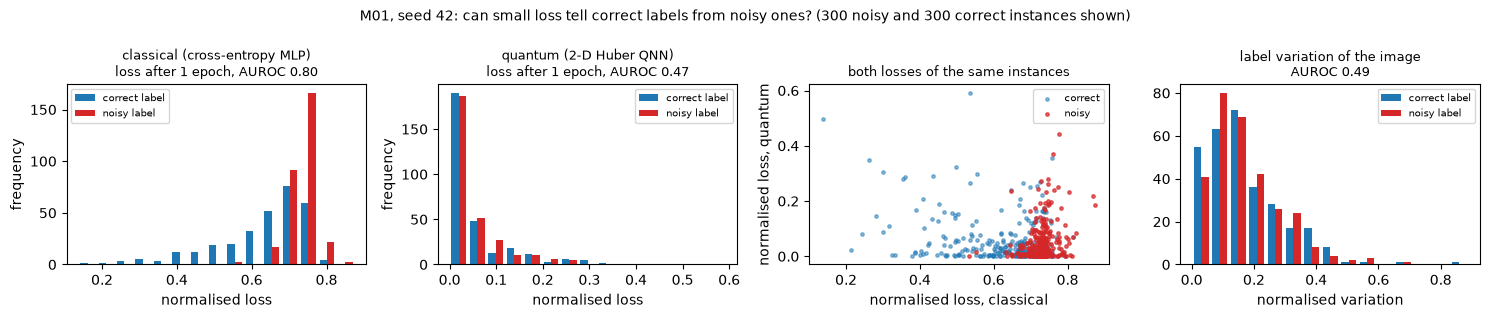

2713 of 15000 queried instances (18.1 %) carry a wrong label (differs from the noise-free victim)
classical (cross-entropy MLP)           0.802
quantum (2-D Huber QNN)                 0.470
label variation (this paper's split)    0.492
[8 s]


In [15]:
t0 = time.time()
tk = TIDX["M01"]; Pm = QUERIES[sd0]["P"]["M01"]; nI = Pm.shape[0] * Pm.shape[1]
Xi, Yi = QUERIES[sd0]["bundle"][0][tk:tk + 1], QUERIES[sd0]["bundle"][1][tk:tk + 1]                    # (1, N*M, 16), (1, N*M, 2)
noisy = (Pm.argmax(-1) != IDEAL_Q[tk][None]).reshape(-1)                                                # the round label differs from the noise-free victim
var_inst = QUERIES[sd0]["bundle"][2][tk].numpy()

# classical model extraction (CloudLeak-style): a small MLP trained one epoch with cross-entropy on the queried labels
torch.manual_seed(SEED)
mlp = nn.Sequential(nn.Linear(16, 16), nn.ReLU(), nn.Linear(16, 2)).double()
opt = torch.optim.Adam(mlp.parameters(), lr=CLONE_LR, weight_decay=CLONE_WD)
order = torch.randperm(nI)
for s in range(0, nI, CLONE_BS):
    idx = order[s:s + CLONE_BS]
    l = per_sample_loss(mlp(Xi[0, idx])[None], Yi[0, idx][None], "ce").mean(); opt.zero_grad(); l.backward(); opt.step()
with torch.no_grad(): loss_cl = per_sample_loss(mlp(Xi[0])[None], Yi[0][None], "ce")[0].numpy()

# QNN extraction (QuantumLeak-style): the victim-architecture QNN trained one epoch with the 2-D Huber loss
qn = clone(1, SEED)
train_single(qn, torch.zeros(1, dtype=torch.long), Xi, Yi, torch.arange(nI)[None, :], 1, CLONE_BS, CLONE_LR, CLONE_WD, SEED, loss="huber")
with torch.no_grad(): loss_q = per_sample_loss(head(qn(Xi)), Yi, "huber")[0].numpy()

norm01 = lambda a: (a - a.min()) / (a.max() - a.min() + 1e-12)
g = np.random.default_rng(SEED); n_no = min(N_OBS4, int(noisy.sum())); n_cl = n_no
i_no = g.choice(np.where(noisy)[0], n_no, replace=False); i_cl = g.choice(np.where(~noisy)[0], n_cl, replace=False)
auc = {"classical (cross-entropy MLP)": roc_auc_score(noisy, loss_cl), "quantum (2-D Huber QNN)": roc_auc_score(noisy, loss_q),
       "label variation (this paper's split)": roc_auc_score(noisy, var_inst)}
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for a, (name, lo) in zip(ax[:2], [("classical (cross-entropy MLP)", loss_cl), ("quantum (2-D Huber QNN)", loss_q)]):
    ln = norm01(lo); a.hist([ln[i_cl], ln[i_no]], bins=15, label=["correct label", "noisy label"], color=["tab:blue", "tab:red"])
    a.set_title(f"{name}\nloss after 1 epoch, AUROC {auc[name]:.2f}", fontsize=9); a.set_xlabel("normalised loss"); a.set_ylabel("frequency"); a.legend(fontsize=7)
ax[2].scatter(norm01(loss_cl)[i_cl], norm01(loss_q)[i_cl], s=6, c="tab:blue", alpha=0.5, label="correct"); ax[2].scatter(norm01(loss_cl)[i_no], norm01(loss_q)[i_no], s=6, c="tab:red", alpha=0.7, label="noisy")
ax[2].set_xlabel("normalised loss, classical"); ax[2].set_ylabel("normalised loss, quantum"); ax[2].set_title("both losses of the same instances", fontsize=9); ax[2].legend(fontsize=7)
ln = norm01(var_inst); ax[3].hist([ln[i_cl], ln[i_no]], bins=15, label=["correct label", "noisy label"], color=["tab:blue", "tab:red"])
ax[3].set_title(f"label variation of the image\nAUROC {auc['label variation (this paper\'s split)']:.2f}", fontsize=9); ax[3].set_xlabel("normalised variation"); ax[3].legend(fontsize=7)
plt.suptitle(f"M01, seed {sd0}: can small loss tell correct labels from noisy ones? ({n_no} noisy and {n_cl} correct instances shown)", fontsize=10); plt.tight_layout(); plt.show()
print(f"{int(noisy.sum())} of {nI} queried instances ({100 * noisy.mean():.1f} %) carry a wrong label (differs from the noise-free victim)")
print(pd.Series(auc, name="AUROC for separating noisy from correct labels (0.5 = no information)").round(3).to_string())
OBS4 = dict(auc_classical=auc["classical (cross-entropy MLP)"], auc_quantum=auc["quantum (2-D Huber QNN)"], auc_var=auc["label variation (this paper's split)"], noisy_share=float(noisy.mean()))
print(f"[{time.time() - t0:.0f} s]")


## 7. The five attacks (paper Sec. 3.1 and 4)

All attacks start from the same queried data of a seed and use the same clone architecture. Since the circuits are tiny, **many clones are trained in one batched PyTorch run** (all tasks, all ensemble members, all forget rates, all grid points together; Adam acts element-wise, so this is identical to
training them one by one).

* **Base** (CloudLeak): one clone on all (image, round) labels, cross-entropy.
* **QLeak** (QuantumLeak): 5 clones on bootstrap samples, 2-D Huber loss, majority vote.
* **CoT**: two clones with classical co-teaching on all data (forget rate tau, ramped over the first epochs); tau is chosen on the validation set.
* **CoT-E**: QuantumLeak's bagged Huber-loss ensemble, every member trained as a co-teaching pair; majority vote.
* **Split co-teaching** (this paper): `SPLIT` by label variation, then `SCOT` on D_r with forget rate f1 and on D_v with f2, two networks teaching each other. Reported twice: with the paper's defaults (Vth 0.1, f1 0, f2 0.3) and with the best (Vth, f1, f2) of a grid chosen on the validation set.
* **Classical models** (random forest, RBF-SVC on a 4000-instance sample, logistic regression) trained on exactly the same queried instances with hard labels, and a random forest trained on D_r only.
* **Reference points:** the noise-free victim and a **clean-label clone** (the same QNN trained on the *true* labels of the same queried images) which shows what is possible without label noise.

Evaluation: accuracy against the true labels of the 1000 test images (the paper's metric) and agreement with the noise-free victim (fidelity).

### 7a. Check of the co-teaching code before it is used

The next cell runs one step of `train_coteach` on a small random problem and compares the new parameters with a plain reference written directly from the paper's description (each network ranks the samples by its own loss, keeps the `(1 - f)` fraction with the smallest loss,
and is updated on the samples that its **peer** selected). A deliberately wrong variant (every network learns from its own selection) must differ.

In [16]:
# One co-teaching step of train_coteach compared with a plain single-pair reference written straight from the paper's description.
n_u, f_u = 64, 0.25
gu = torch.Generator().manual_seed(0)
Xu = torch.randn(1, n_u, 16, dtype=torch.float64, generator=gu); Yu = F.softmax(torch.randn(1, n_u, 2, dtype=torch.float64, generator=gu) * 2, -1)
Vu = torch.rand(1, n_u, dtype=torch.float64, generator=gu)
for kind in ["ce", "huber"]:
    a1, b1 = BQNN(1, 4, 2, [5], init_std=0.5), BQNN(1, 4, 2, [6], init_std=0.5)                       # the engine (one batch = the whole set, so the batch order is irrelevant)
    train_coteach(a1, b1, torch.zeros(1, dtype=torch.long), Xu, Yu, Vu, torch.tensor([float("inf")], dtype=torch.float64), torch.tensor([f_u], dtype=torch.float64),
                  torch.zeros(1, dtype=torch.float64), 1, n_u, 1e-2, CLONE_WD, 0, loss=kind, ramp=0)
    a2, b2 = BQNN(1, 4, 2, [5], init_std=0.5), BQNN(1, 4, 2, [6], init_std=0.5)                       # the reference
    opt_u = torch.optim.Adam(list(a2.parameters()) + list(b2.parameters()), lr=1e-2, weight_decay=CLONE_WD)
    lA_u = per_sample_loss(head(a2(Xu)), Yu, kind)[0]; lB_u = per_sample_loss(head(b2(Xu)), Yu, kind)[0]
    keep_u = int(np.ceil((1 - f_u) * n_u)); selA_u = torch.argsort(lA_u.detach())[:keep_u]; selB_u = torch.argsort(lB_u.detach())[:keep_u]
    (lA_u[selB_u].mean() + lB_u[selA_u].mean()).backward(); opt_u.step()                               # Q1 learns from Q2's small-loss samples and vice versa
    a3, b3 = BQNN(1, 4, 2, [5], init_std=0.5), BQNN(1, 4, 2, [6], init_std=0.5)                       # a wrong variant: every network learns from its own selection
    opt_w = torch.optim.Adam(list(a3.parameters()) + list(b3.parameters()), lr=1e-2, weight_decay=CLONE_WD)
    (per_sample_loss(head(a3(Xu)), Yu, kind)[0][selA_u].mean() + per_sample_loss(head(b3(Xu)), Yu, kind)[0][selB_u].mean()).backward(); opt_w.step()
    d_ok = max((a1.params - a2.params).abs().max().item(), (b1.params - b2.params).abs().max().item()); d_wrong = (a1.params - a3.params).abs().max().item()
    print(f"loss '{kind}': max |parameter difference| engine vs reference {d_ok:.1e}; the self-selection variant would differ by {d_wrong:.1e}")
    assert d_ok < 1e-12 and d_wrong > 1e-3
print("The co-teaching engine performs exactly the update of the paper's description (cross-update with the peer's small-loss samples).")

# Second check: pairs with different numbers of mini-batches must not disturb each other. Pair 0 has only robust data, pair 1 only vulnerable data, so
# in every epoch one of the two phases is empty for each pair; trained together they must end exactly where they end when trained alone.
def run_pairs(seeds, vths, f1s, f2s):
    K_ = len(seeds)
    a_, b_ = BQNN(K_, 4, 2, [s for s in seeds], init_std=0.5), BQNN(K_, 4, 2, [s + 100 for s in seeds], init_std=0.5)
    train_coteach(a_, b_, torch.zeros(K_, dtype=torch.long), Xu, Yu, Vu, torch.tensor(vths, dtype=torch.float64), torch.tensor(f1s, dtype=torch.float64),
                  torch.tensor(f2s, dtype=torch.float64), 3, n_u, 1e-2, CLONE_WD, 0, loss="ce", ramp=0)
    return a_.params.detach().clone(), b_.params.detach().clone()
pA, pB = run_pairs([5, 7], [float("inf"), -1.0], [0.25, 0.0], [0.0, 0.25])                              # together
sA0, sB0 = run_pairs([5], [float("inf")], [0.25], [0.0]); sA1, sB1 = run_pairs([7], [-1.0], [0.0], [0.25])      # alone
d_sep = max((pA[0] - sA0[0]).abs().max().item(), (pB[0] - sB0[0]).abs().max().item(), (pA[1] - sA1[0]).abs().max().item(), (pB[1] - sB1[0]).abs().max().item())
print(f"pairs trained together versus alone: max |parameter difference| {d_sep:.1e}")
assert d_sep < 1e-12
print("A pair that has run out of mini-batches is left untouched (no stray Adam momentum or weight-decay steps).")


loss 'ce': max |parameter difference| engine vs reference 3.5e-18; the self-selection variant would differ by 2.0e-02


loss 'huber': max |parameter difference| engine vs reference 6.9e-18; the self-selection variant would differ by 2.0e-02
The co-teaching engine performs exactly the update of the paper's description (cross-update with the peer's small-loss samples).


pairs trained together versus alone: max |parameter difference| 2.2e-16
A pair that has run out of mini-batches is left untouched (no stray Adam momentum or weight-decay steps).


In [17]:
T_N = len(TASKS); E_N = ENSEMBLE_SIZE; R_N = N_INIT
IDEAL_TEST = torch.stack([VIC[t]["ideal_pred"] for t in TASKS])                 # noise-free victim's answers on the test images (T, Nte)
INF = float("inf")
ident = lambda K, n: torch.arange(n)[None, :].expand(K, n).contiguous()

def eval_models(model, ct):
    """validation accuracy, test accuracy (both against the TRUE labels), agreement with the noise-free victim, test predictions."""
    pv = predict_logits(model, ct, Xval_all).argmax(-1); pt = predict_logits(model, ct, Xte_all).argmax(-1)
    return (100 * (pv == yval_all[ct]).double().mean(1)).numpy(), (100 * (pt == yte_all[ct]).double().mean(1)).numpy(), \
           (100 * (pt == IDEAL_TEST[ct]).double().mean(1)).numpy(), pt.numpy()

def vote(models_pred, T, E):
    """majority vote of E ensemble members per task: predictions (T*E, Nte) -> (T, Nte); QuantumLeak's decision fusion."""
    return (models_pred.reshape(T, E, -1).sum(1) * 2 > E).astype(int)

def acc_of(pred, ti, which="te"):
    y = yte_all[ti].numpy() if which == "te" else yval_all[ti].numpy()
    return 100 * (pred == y).mean()

def per_cfg(arr, G):
    """(T*G*R, ...) -> (T, G, R, ...) for models laid out as (task, configuration, restart)."""
    return arr.reshape(T_N, G, R_N, *arr.shape[1:])

def run_methods(seed):
    Xs, Ys, VAR = QUERIES[seed]["bundle"]; n = Xs.shape[1]; g = torch.Generator().manual_seed(seed)
    rows, grid_rows, preds, times = [], [], {}, {}
    def add(task, method, val, test, agree, pred, t_s):
        rows.append(dict(seed=seed, task=task, method=method, val_acc=val, acc=test, agree=agree, time_s=t_s)); preds[(seed, task, method)] = pred

    # ---- reference points: the noise-free victim and a clone trained on the TRUE labels of the same queried images ----
    for ti, t in enumerate(TASKS):
        add(t, "victim (ideal, noise-free)", np.nan, 100 * VIC[t]["ideal_acc"], 100.0, IDEAL_TEST[ti].numpy(), np.nan)
    t0 = time.time(); ct_r = ct_task.repeat_interleave(R_N)
    Ytrue = F.one_hot(torch.tensor(np.stack([np.tile(TD[t]["y_q"], M_ROUNDS) for t in TASKS])), 2).double()
    clean = clone(T_N * R_N, seed + 500)
    train_single(clean, ct_r, Xs, Ytrue, ident(T_N * R_N, n), CLONE_EPOCHS, CLONE_BS, CLONE_LR, CLONE_WD, seed, "ce")
    v, a, ag, p = eval_models(clean, ct_r); tt = time.time() - t0
    v, a, ag, p = per_cfg(v, 1), per_cfg(a, 1), per_cfg(ag, 1), per_cfg(p, 1)
    for ti, t in enumerate(TASKS): add(t, "clean-label clone (upper bound)", v[ti, 0].mean(), a[ti, 0].mean(), ag[ti, 0].mean(), p[ti, 0, 0], tt / T_N)

    # ---- Base: CloudLeak applied to a QNN = one clone of the victim architecture on all queried (image, round) labels ----
    t0 = time.time()
    base = clone(T_N * R_N, seed)
    train_single(base, ct_r, Xs, Ys, ident(T_N * R_N, n), CLONE_EPOCHS, CLONE_BS, CLONE_LR, CLONE_WD, seed, "ce")
    v, a, ag, p = eval_models(base, ct_r); tt = time.time() - t0; times["Base"] = tt
    v, a, ag, p = per_cfg(v, 1), per_cfg(a, 1), per_cfg(ag, 1), per_cfg(p, 1)
    for ti, t in enumerate(TASKS): add(t, "Base (CloudLeak)", v[ti, 0].mean(), a[ti, 0].mean(), ag[ti, 0].mean(), p[ti, 0, 0], tt / T_N)

    # ---- QLeak: QuantumLeak = ensemble of E bagged clones trained with the 2-D Huber loss, majority vote ----
    t0 = time.time()
    ct_e = ct_task.repeat_interleave(E_N); boot = torch.randint(0, n, (T_N * E_N, n), generator=g)
    leak = clone(T_N * E_N, seed + 1000)
    train_single(leak, ct_e, Xs, Ys, boot, CLONE_EPOCHS, CLONE_BS, CLONE_LR, CLONE_WD, seed + 1, "huber")
    pv = predict_logits(leak, ct_e, Xval_all).argmax(-1).numpy(); pt = predict_logits(leak, ct_e, Xte_all).argmax(-1).numpy()
    vv, vt = vote(pv, T_N, E_N), vote(pt, T_N, E_N); tt = time.time() - t0; times["QLeak"] = tt
    for ti, t in enumerate(TASKS): add(t, "QLeak (QuantumLeak)", acc_of(vv[ti], ti, "va"), acc_of(vt[ti], ti), 100 * (vt[ti] == IDEAL_TEST[ti].numpy()).mean(), vt[ti], tt / T_N)

    # ---- CoT: classical co-teaching on two QNNs (no data split); forget rate tau tuned on the validation set ----
    t0 = time.time(); nt = len(TAU_GRID); K = T_N * nt * R_N
    ct_c = ct_task.repeat_interleave(nt * R_N); tau = torch.tensor(TAU_GRID, dtype=torch.float64).repeat_interleave(R_N).repeat(T_N)
    cA, cB = clone(K, seed + 2000), clone(K, seed + 12000)
    train_coteach(cA, cB, ct_c, Xs, Ys, VAR, torch.full((K,), INF), tau, torch.zeros(K), CLONE_EPOCHS, CLONE_BS, CLONE_LR, CLONE_WD, seed + 2,
                  loss="ce", ramp=COT_RAMP_EPOCHS)
    v, a, ag, p = eval_models(cA, ct_c); tt = time.time() - t0; times["CoT"] = tt; tau_best = {}
    v, a, ag, p = per_cfg(v, nt), per_cfg(a, nt), per_cfg(ag, nt), per_cfg(p, nt)
    for ti, t in enumerate(TASKS):
        b = int(np.argmax(v[ti].mean(1))); tau_best[t] = TAU_GRID[b]
        for k in range(nt): grid_rows.append(dict(seed=seed, task=t, kind="cot", vth=np.nan, f1=TAU_GRID[k], f2=np.nan, val=v[ti, k].mean(), test=a[ti, k].mean(), agree=ag[ti, k].mean(), share_robust=100.0))
        add(t, "CoT (classical co-teaching)", v[ti, b].mean(), a[ti, b].mean(), ag[ti, b].mean(), p[ti, b, 0], tt / T_N)

    # ---- CoT-E: an ensemble of E bagged Huber-loss clones trained with co-teaching, majority vote ----
    t0 = time.time()
    tau_e = torch.tensor([tau_best[t] for t in TASKS], dtype=torch.float64).repeat_interleave(E_N)
    boot2 = torch.randint(0, n, (T_N * E_N, n), generator=g)
    eA, eB = clone(T_N * E_N, seed + 3000), clone(T_N * E_N, seed + 13000)
    train_coteach(eA, eB, ct_e, Xs, Ys, VAR, torch.full((T_N * E_N,), INF), tau_e, torch.zeros(T_N * E_N), CLONE_EPOCHS, CLONE_BS, CLONE_LR, CLONE_WD, seed + 3,
                  loss="huber", ramp=COT_RAMP_EPOCHS, slot_idx=boot2)
    pv = predict_logits(eA, ct_e, Xval_all).argmax(-1).numpy(); pt = predict_logits(eA, ct_e, Xte_all).argmax(-1).numpy()
    vv, vt = vote(pv, T_N, E_N), vote(pt, T_N, E_N); tt = time.time() - t0; times["CoT-E"] = tt
    for ti, t in enumerate(TASKS): add(t, "CoT-E (QuantumLeak + co-teaching)", acc_of(vv[ti], ti, "va"), acc_of(vt[ti], ti), 100 * (vt[ti] == IDEAL_TEST[ti].numpy()).mean(), vt[ti], tt / T_N)

    # ---- split co-teaching (this paper): grid over (Vth, f1, f2), best configuration chosen on the validation set ----
    t0 = time.time()
    cfgs = list(itertools.product(VTH_GRID, F1_GRID, F2_GRID)); G = len(cfgs); K = T_N * G * R_N
    ct_g = ct_task.repeat_interleave(G * R_N)
    rep = lambda col: torch.tensor([c[col] for c in cfgs], dtype=torch.float64).repeat_interleave(R_N).repeat(T_N)
    sA, sB = clone(K, seed + 4000), clone(K, seed + 14000)
    train_coteach(sA, sB, ct_g, Xs, Ys, VAR, rep(0), rep(1), rep(2), CLONE_EPOCHS, CLONE_BS, CLONE_LR, CLONE_WD, seed + 4, loss="ce", ramp=0)
    v, a, ag, p = eval_models(sA, ct_g); tt = time.time() - t0; times["Split co-teaching"] = tt
    v, a, ag, p = per_cfg(v, G), per_cfg(a, G), per_cfg(ag, G), per_cfg(p, G)
    dflt = cfgs.index((PAPER_DEFAULT["vth"], PAPER_DEFAULT["f1"], PAPER_DEFAULT["f2"]))
    for ti, t in enumerate(TASKS):
        b = int(np.argmax(v[ti].mean(1))); varr = VAR[ti].numpy()
        for k, c in enumerate(cfgs):
            grid_rows.append(dict(seed=seed, task=t, kind="split", vth=c[0], f1=c[1], f2=c[2], val=v[ti, k].mean(), test=a[ti, k].mean(), agree=ag[ti, k].mean(), share_robust=100 * (varr <= c[0]).mean()))
        add(t, "Split co-teaching (this paper, tuned)", v[ti, b].mean(), a[ti, b].mean(), ag[ti, b].mean(), p[ti, b, 0], tt / T_N)
        rows[-1]["config"] = str(cfgs[b])
        add(t, "Split co-teaching (paper defaults)", v[ti, dflt].mean(), a[ti, dflt].mean(), ag[ti, dflt].mean(), p[ti, dflt, 0], tt / T_N)
        idx = (ti * G + b) * R_N
        MODELS[(seed, t)] = dict(Q1=sA.params[idx].detach().numpy().copy(), Q2=sB.params[idx].detach().numpy().copy(), cfg=cfgs[b])

    # ---- classical models on exactly the same queried data (hard labels = arg-max of every round) ----
    t0 = time.time()
    for ti, t in enumerate(TASKS):
        Xc = Xs[ti].numpy(); yc = Ys[ti].numpy().argmax(1); Xte_n = TD[t]["A_te"]; vsc = VAR[ti].numpy(); rob = vsc <= PAPER_DEFAULT["vth"]
        sub = np.random.default_rng(seed + ti).choice(len(Xc), min(4000, len(Xc)), replace=False)
        for name, mdl, Xa, ya in [("Random forest (all labels)", RandomForestClassifier(100, min_samples_leaf=2, random_state=SEED, n_jobs=1), Xc, yc),
                                  ("Random forest (robust set D_r only)", RandomForestClassifier(100, min_samples_leaf=2, random_state=SEED, n_jobs=1), Xc[rob], yc[rob]),
                                  ("SVC rbf (all labels, 4000 sampled)", SVC(kernel="rbf"), Xc[sub], yc[sub]),
                                  ("Logistic regression (all labels)", LogisticRegression(max_iter=500), Xc, yc)]:
            ok = len(np.unique(ya)) > 1
            pr = mdl.fit(Xa, ya).predict(Xte_n) if ok else np.full(len(Xte_n), ya[0])
            prv = mdl.predict(TD[t]["A_val"]) if ok else np.full(len(TD[t]["A_val"]), ya[0])
            add(t, name, 100 * (prv == TD[t]["y_val"]).mean(), 100 * (pr == TD[t]["y_te"]).mean(), 100 * (pr == IDEAL_TEST[ti].numpy()).mean(), pr, np.nan)
    times["classical"] = time.time() - t0
    return rows, grid_rows, preds, times

ROWS, GRID, PREDS, TIMES, MODELS = [], [], {}, {}, {}
for seed in SEEDS:
    t0 = time.time()
    r, gr, pr, tm = run_methods(seed)
    ROWS += r; GRID += gr; PREDS.update(pr); TIMES[seed] = tm
    print(f"seed {seed}: all methods trained [{time.time() - t0:.0f} s]  stage times (s): " + ", ".join(f"{k} {v:.0f}" for k, v in tm.items()), flush=True)
RES = pd.DataFrame(ROWS); GRID_DF = pd.DataFrame(GRID)


seed 42: all methods trained [1099 s]  stage times (s): Base 36, QLeak 63, CoT 166, CoT-E 139, Split co-teaching 601, classical 49


seed 43: all methods trained [873 s]  stage times (s): Base 28, QLeak 49, CoT 113, CoT-E 111, Split co-teaching 481, classical 61


## 8. Results: Fig. 2 and Fig. 6

The first table is the paper's Fig. 6 for our simulated cloud; the Fig. 2 panel is the M01 slice with the noise-free victim. The paper's headline numbers are the improvements over Base (+6.5 ... +9.5) and over QuantumLeak (+0.1 ... +3.7).

Test accuracy (%) of the stolen model against the TRUE labels, mean over 2 seed(s) (3000 queried images x 5 rounds, 1000 test images)
task                                    M01   M78   Ftt   Fds   Fss  mean
method                                                                   
victim (ideal, noise-free)             98.3  87.3  93.8  96.1  96.4  94.4
clean-label clone (upper bound)        97.9  87.9  94.4  95.3  95.9  94.3
Base (CloudLeak)                       88.7  70.4  66.6  81.7  86.3  78.7
QLeak (QuantumLeak)                    87.8  69.2  64.8  83.5  86.5  78.4
CoT (classical co-teaching)            88.7  71.3  65.7  85.4  88.4  79.9
CoT-E (QuantumLeak + co-teaching)      83.8  66.9  62.3  72.1  86.4  74.3
Split co-teaching (paper defaults)     90.6  70.2  65.9  84.3  87.4  79.7
Split co-teaching (this paper, tuned)  90.3  73.0  71.6  85.6  88.2  81.7
Random forest (all labels)             90.2  79.6  70.3  88.4  93.4  84.4
Random forest (robust set D_r only)    91.0  80.6  6

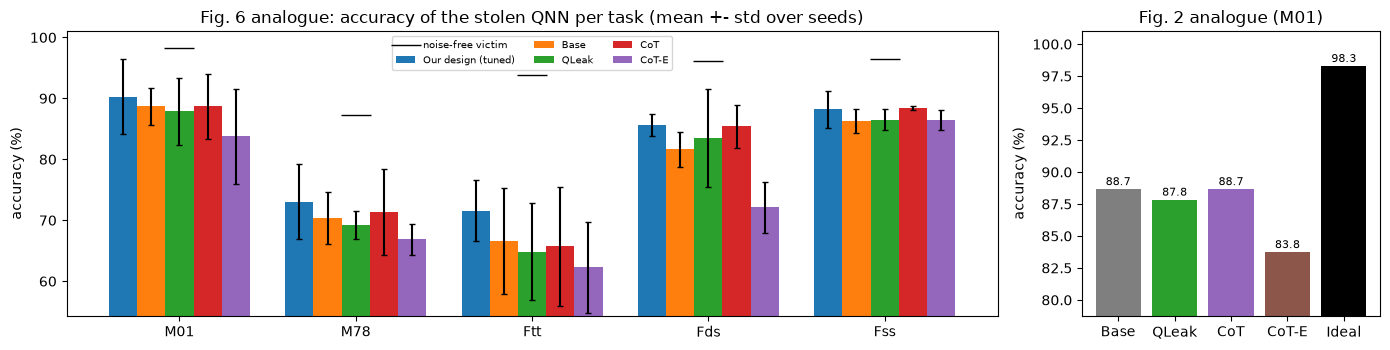


Improvement of the split co-teaching clone in accuracy points (paper: +6.5 ... +9.5 over Base, +0.1 ... +3.7 over QuantumLeak)
      ours (tuned) - Base  ours (tuned) - QLeak  ours (paper defaults) - Base  ours (paper defaults) - QLeak
task                                                                                                        
M01                   1.6                   2.5                           1.9                            2.8
M78                   2.6                   3.8                          -0.2                            0.9
Ftt                   5.0                   6.7                          -0.7                            1.0
Fds                   3.9                   2.1                           2.6                            0.8
Fss                   1.9                   1.7                           1.0                            0.9


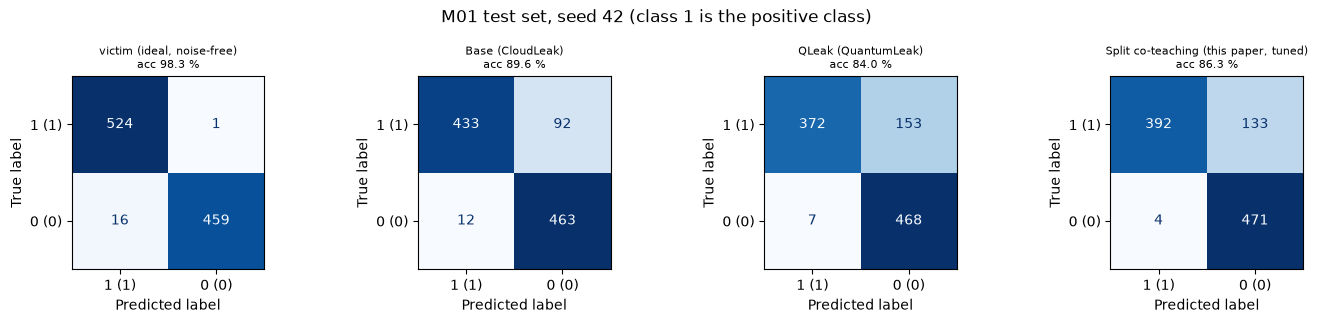


Wall-clock seconds per training stage (the stages train many models at once; shared CPU)
    Base  QLeak    CoT  CoT-E  Split co-teaching  classical
42  36.0   63.0  166.0  139.0              601.0       49.0
43  28.0   49.0  113.0  111.0              481.0       61.0


In [18]:
MAIN = ["victim (ideal, noise-free)", "clean-label clone (upper bound)", "Base (CloudLeak)", "QLeak (QuantumLeak)", "CoT (classical co-teaching)",
        "CoT-E (QuantumLeak + co-teaching)", "Split co-teaching (paper defaults)", "Split co-teaching (this paper, tuned)"]
CLASSICAL = ["Random forest (all labels)", "Random forest (robust set D_r only)", "SVC rbf (all labels, 4000 sampled)", "Logistic regression (all labels)"]
tab = lambda col, fn, rows: RES.groupby(["method", "task"])[col].agg(fn).unstack().reindex(index=rows, columns=TASKS)
acc_tab = tab("acc", "mean", MAIN + CLASSICAL)
std_tab = tab("acc", "std", MAIN + CLASSICAL)
acc_tab["mean"] = acc_tab.mean(1)
print(f"Test accuracy (%) of the stolen model against the TRUE labels, mean over {len(SEEDS)} seed(s) ({N_QUERY} queried images x {M_ROUNDS} rounds, {N_TEST} test images)")
print(acc_tab.round(1).to_string())
if len(SEEDS) > 1:
    print("\nstandard deviation over seeds (percentage points)"); print(std_tab.round(1).to_string())
agree_tab = tab("agree", "mean", MAIN[1:] + CLASSICAL); agree_tab["mean"] = agree_tab.mean(1)
print("\nFidelity: agreement (%) of the stolen model with the noise-free victim on the test images")
print(agree_tab.round(1).to_string())

# ---- Fig. 6 analogue: accuracy of this work and the four baselines ----
SHOW = [("Split co-teaching (this paper, tuned)", "Our design (tuned)"), ("Base (CloudLeak)", "Base"), ("QLeak (QuantumLeak)", "QLeak"),
        ("CoT (classical co-teaching)", "CoT"), ("CoT-E (QuantumLeak + co-teaching)", "CoT-E")]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw=dict(width_ratios=[len(TASKS), 1.6]))
w = 0.16
for j, (m, lab) in enumerate(SHOW):
    mu = acc_tab.loc[m, TASKS].values.astype(float); sd = np.nan_to_num(std_tab.loc[m, TASKS].values.astype(float))
    ax[0].bar(np.arange(len(TASKS)) + (j - 2) * w, mu, w, yerr=sd if len(SEEDS) > 1 else None, capsize=2, label=lab)
ax[0].set_xticks(range(len(TASKS))); ax[0].set_xticklabels(TASKS); ax[0].set_ylim(max(40, np.nanmin(acc_tab.loc[[m for m, _ in SHOW], TASKS].values) - 8), 101)
ax[0].plot(range(len(TASKS)), [100 * VIC[t]["ideal_acc"] for t in TASKS], "k_", ms=22, label="noise-free victim"); ax[0].set_ylabel("accuracy (%)")
ax[0].set_title("Fig. 6 analogue: accuracy of the stolen QNN per task (mean +- std over seeds)"); ax[0].legend(fontsize=7, ncol=3)
# ---- Fig. 2 analogue: M01, 5 queries ----
f2 = [("Base", "Base (CloudLeak)"), ("QLeak", "QLeak (QuantumLeak)"), ("CoT", "CoT (classical co-teaching)"), ("CoT-E", "CoT-E (QuantumLeak + co-teaching)"), ("Ideal", "victim (ideal, noise-free)")]
vals = [acc_tab.loc[m, "M01"] for _, m in f2]
ax[1].bar([l for l, _ in f2], vals, color=["tab:gray", "tab:green", "tab:purple", "tab:brown", "k"]); ax[1].set_ylim(min(vals) - 5, 101)
for i, v_ in enumerate(vals): ax[1].text(i, v_ + 0.3, f"{v_:.1f}", ha="center", fontsize=8)
ax[1].set_title("Fig. 2 analogue (M01)"); ax[1].set_ylabel("accuracy (%)")
plt.tight_layout(); plt.show()

# ---- improvements, the paper's headline numbers ----
imp = pd.DataFrame({"ours (tuned) - Base": acc_tab.loc["Split co-teaching (this paper, tuned)", TASKS] - acc_tab.loc["Base (CloudLeak)", TASKS],
                    "ours (tuned) - QLeak": acc_tab.loc["Split co-teaching (this paper, tuned)", TASKS] - acc_tab.loc["QLeak (QuantumLeak)", TASKS],
                    "ours (paper defaults) - Base": acc_tab.loc["Split co-teaching (paper defaults)", TASKS] - acc_tab.loc["Base (CloudLeak)", TASKS],
                    "ours (paper defaults) - QLeak": acc_tab.loc["Split co-teaching (paper defaults)", TASKS] - acc_tab.loc["QLeak (QuantumLeak)", TASKS]})
print("\nImprovement of the split co-teaching clone in accuracy points (paper: +6.5 ... +9.5 over Base, +0.1 ... +3.7 over QuantumLeak)")
print(imp.round(1).to_string())

# ---- confusion matrices of the first task / seed (class 1 = positive) ----
t_cm, s_cm = TASKS[0], SEEDS[0]; yt = TD[t_cm]["y_te"]
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
for a, m in zip(ax, ["victim (ideal, noise-free)", "Base (CloudLeak)", "QLeak (QuantumLeak)", "Split co-teaching (this paper, tuned)"]):
    pred = PREDS[(s_cm, t_cm, m)]
    ConfusionMatrixDisplay(confusion_matrix(yt, pred, labels=[1, 0]), display_labels=[f"{class_names(t_cm)[1]} (1)", f"{class_names(t_cm)[0]} (0)"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{m}\nacc {100 * (pred == yt).mean():.1f} %", fontsize=8)
plt.suptitle(f"{t_cm} test set, seed {s_cm} (class 1 is the positive class)"); plt.tight_layout(); plt.show()

tm_df = pd.DataFrame(TIMES).T
print("\nWall-clock seconds per training stage (the stages train many models at once; shared CPU)"); print(tm_df.round(0).to_string())


## 9. Sensitivity to Vth, f1 and f2 (paper Figs. 7 to 9)

M01, every configuration trained from scratch; accuracy on the test images (the paper's curves are test accuracies of single runs on hardware). The sweeps keep the other settings as in the figure captions:
Fig. 7 varies Vth at f1 = 0, f2 = 0.1; Fig. 8 varies f1 at Vth = 0.1, f2 = 0.3; Fig. 9 varies f2 at Vth = 0.1, f1 = 0. The paper also states that Vth = 0.15 puts 72.6 % of the M01 data into D_r; the share is printed in the table.

  sensitivity + ablation, seed 42 done [347 s]


  sensitivity + ablation, seed 43 done [627 s]


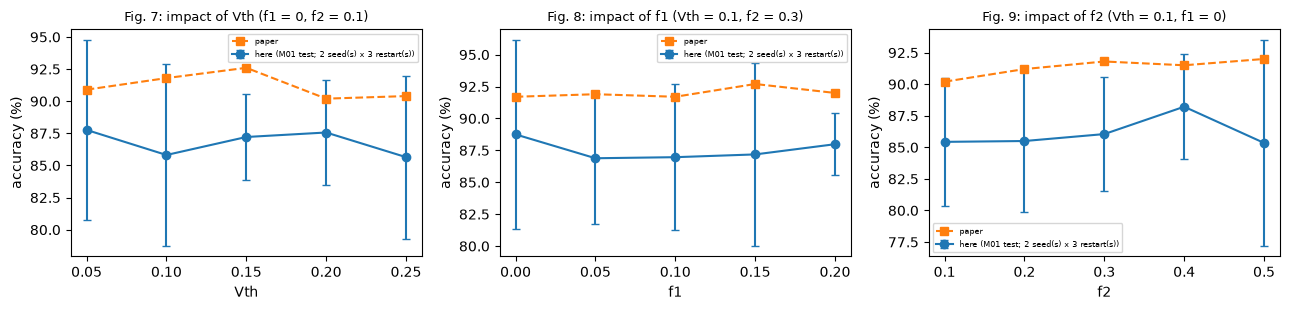

                      acc  share_robust
sweep vth  f1   f2                     
Vth   0.05 0.00 0.1  87.8          12.7
      0.10 0.00 0.1  85.8          33.2
      0.15 0.00 0.1  87.2          52.1
      0.20 0.00 0.1  87.6          66.7
      0.25 0.00 0.1  85.6          77.2
f1    0.10 0.00 0.3  88.8          33.2
           0.05 0.3  86.9          33.2
           0.10 0.3  87.0          33.2
           0.15 0.3  87.2          33.2
           0.20 0.3  88.0          33.2
f2    0.10 0.00 0.1  85.4          33.2
                0.2  85.5          33.2
                0.3  86.1          33.2
                0.4  88.2          33.2
                0.5  85.4          33.2
[628 s]


In [19]:
t0 = time.time(); tM = TIDX["M01"]; TV = len(TASKS)                           # index TV = a "virtual task": M01 queries with a RANDOM variation score (ablation)
sweep_cfg = [("Vth", v, 0.0, 0.1) for v in SWEEP_VTH] + [("f1", 0.10, f, 0.3) for f in SWEEP_F1] + [("f2", 0.10, 0.0, f) for f in SWEEP_F2]     # Figs. 7, 8, 9
SW_ROWS, AB_ROWS = [], []
for seed in SEEDS:
    Xs, Ys, VAR = QUERIES[seed]["bundle"]; n = Xs.shape[1]; Nimg = n // M_ROUNDS
    share = float((VAR[tM].numpy() <= PAPER_DEFAULT["vth"]).mean())                     # share of M01 in D_r at the paper's Vth
    g_ab = torch.Generator().manual_seed(seed + 77)
    VAR_rand = torch.rand(Nimg, generator=g_ab, dtype=torch.float64).repeat(M_ROUNDS)    # random score, identical for all rounds of an image
    Xs_e, Ys_e, VAR_e = torch.cat([Xs, Xs[tM:tM + 1]]), torch.cat([Ys, Ys[tM:tM + 1]]), torch.cat([VAR, VAR_rand[None]])
    f_avg = (1 - share) * PAPER_DEFAULT["f2"] + share * PAPER_DEFAULT["f1"]
    # (name, task row, Vth, f1, f2): Figs. 7-9 first, then the ablation variants
    cfgs = [(f"sweep {c[0]}", tM, c[1], c[2], c[3]) for c in sweep_cfg] + \
           [("variation split (paper)", tM, PAPER_DEFAULT["vth"], PAPER_DEFAULT["f1"], PAPER_DEFAULT["f2"]),
            ("random split, same share in D_r", TV, share, PAPER_DEFAULT["f1"], PAPER_DEFAULT["f2"]),
            ("no split, one forget rate (same average)", tM, INF, f_avg, 0.0),
            ("no forgetting (f = 0): two plain QNNs", tM, INF, 0.0, 0.0)]
    NC = len(cfgs); K = NC * N_INIT_SWEEP
    ctM = torch.tensor([c[1] for c in cfgs]).repeat_interleave(N_INIT_SWEEP)
    col = lambda j: torch.tensor([c[j] for c in cfgs], dtype=torch.float64).repeat_interleave(N_INIT_SWEEP)
    sA, sB = clone(K, seed + 6000), clone(K, seed + 16000)
    train_coteach(sA, sB, ctM, Xs_e, Ys_e, VAR_e, col(2), col(3), col(4), CLONE_EPOCHS, CLONE_BS, CLONE_LR, CLONE_WD, seed + 6, loss="ce", ramp=0)
    ctE = torch.full((K,), tM, dtype=torch.long)                                          # evaluation always on the M01 test set
    v, a, ag, p = eval_models(sA, ctE); a = a.reshape(NC, N_INIT_SWEEP); v = v.reshape(NC, N_INIT_SWEEP)
    for k, c in enumerate(cfgs):
        if k < len(sweep_cfg):
            SW_ROWS.append(dict(seed=seed, sweep=sweep_cfg[k][0], vth=c[2], f1=c[3], f2=c[4], val=v[k].mean(), acc=a[k].mean(), share_robust=100 * (VAR[tM].numpy() <= c[2]).mean()))
        else:
            AB_ROWS += [dict(seed=seed, variant=c[0], init=r, acc=a[k, r]) for r in range(N_INIT_SWEEP)]
    print(f"  sensitivity + ablation, seed {seed} done [{time.time() - t0:.0f} s]", flush=True)
SW = pd.DataFrame(SW_ROWS); AB = pd.DataFrame(AB_ROWS)
PAPER_SW = {"Vth": ([0.05, 0.10, 0.15, 0.20, 0.25], [90.9, 91.8, 92.6, 90.2, 90.4]), "f1": ([0, 0.05, 0.10, 0.15, 0.20], [91.7, 91.9, 91.7, 92.7, 92.0]),
            "f2": ([0.1, 0.2, 0.3, 0.4, 0.5], [90.2, 91.2, 91.8, 91.5, 92.0])}
key = {"Vth": "vth", "f1": "f1", "f2": "f2"}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a_, (name, ttl) in zip(ax, [("Vth", "Fig. 7: impact of Vth (f1 = 0, f2 = 0.1)"), ("f1", "Fig. 8: impact of f1 (Vth = 0.1, f2 = 0.3)"), ("f2", "Fig. 9: impact of f2 (Vth = 0.1, f1 = 0)")]):
    sub = SW[SW.sweep == name].groupby(key[name]).acc.agg(["mean", "std"]).fillna(0)
    a_.errorbar(sub.index, sub["mean"], yerr=sub["std"] if len(SEEDS) > 1 else None, fmt="o-", capsize=3, label=f"here (M01 test; {len(SEEDS)} seed(s) x {N_INIT_SWEEP} restart(s))")
    a_.plot(*PAPER_SW[name], "s--", label="paper"); a_.set_xlabel(name); a_.set_ylabel("accuracy (%)"); a_.set_title(ttl, fontsize=9); a_.legend(fontsize=6)
plt.tight_layout(); plt.show()
sw_tab = SW.groupby(["sweep", "vth", "f1", "f2"]).agg(acc=("acc", "mean"), share_robust=("share_robust", "mean")).round(1)
print(sw_tab.to_string())
print(f"[{time.time() - t0:.0f} s]")


### 9b. Ablation (not in the paper): does the split carry information?

Split co-teaching differs from classical co-teaching in two ways: two different forget rates and the rule that decides which sample gets which. To see whether the *rule* (label variation) matters, the cell below keeps the paper's defaults and replaces the variation by a random
score with the same share of D_r, then by one forget rate with the same average, then by no forgetting at all. These runs are trained in the same batch as the sweeps of Section 9.

Ablation on M01 (paper defaults, Q1 of the pair; trained together with the sweeps above): is the split informative, or is it just two forget rates?
                                          M01 test acc mean (%)  std over seeds x restarts
variant                                                                                   
variation split (paper)                                   87.67                       4.19
random split, same share in D_r                           87.83                       4.93
no split, one forget rate (same average)                  88.18                       4.38
no forgetting (f = 0): two plain QNNs                     86.75                       5.36


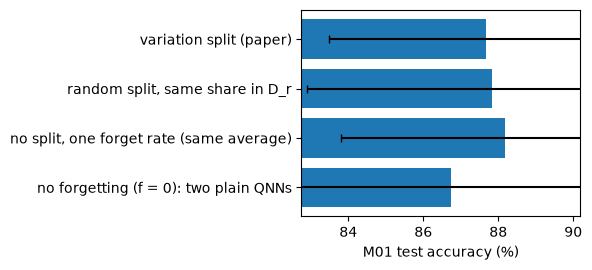

In [20]:
ab_tab = AB.groupby("variant", sort=False).acc.agg(["mean", "std"]).round(2)
ab_tab.columns = ["M01 test acc mean (%)", "std over seeds x restarts"]
print("Ablation on M01 (paper defaults, Q1 of the pair; trained together with the sweeps above): is the split informative, or is it just two forget rates?")
print(ab_tab.to_string())
plt.figure(figsize=(6, 2.8)); plt.barh(ab_tab.index[::-1], ab_tab["M01 test acc mean (%)"][::-1], xerr=ab_tab["std over seeds x restarts"][::-1].fillna(0), capsize=3)
plt.xlim(ab_tab["M01 test acc mean (%)"].min() - 4, ab_tab["M01 test acc mean (%)"].max() + 2); plt.xlabel("M01 test accuracy (%)"); plt.tight_layout(); plt.show()


## Quantum Circuit Architecture

Every gate-based quantum model of this notebook has the same architecture: 4 qubits, amplitude encoding, two repeated VQC layers (RZ-RY-RZ on every qubit, then a ring of CRX gates), measurement of all qubits. The victim runs on the simulated cloud
(Qiskit object `cloud_circuit`, drawn below as logical circuit; the executed version is transpiled to the basis gates rx, ry, rz, cx, id). The two networks Q1 and Q2 of the trained split co-teaching pair for M01 are drawn with their trained parameters, from
the same gate list the PyTorch simulator runs; the equivalence of the Qiskit and the PyTorch description of the trained Q1 is asserted. Base, every QLeak and CoT-E member, CoT and the split co-teaching pair differ only in their parameter values.

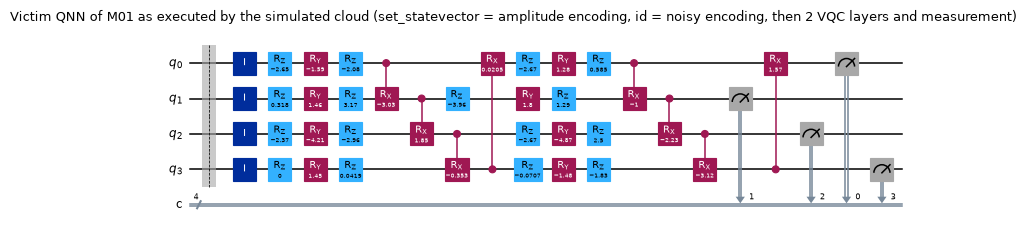

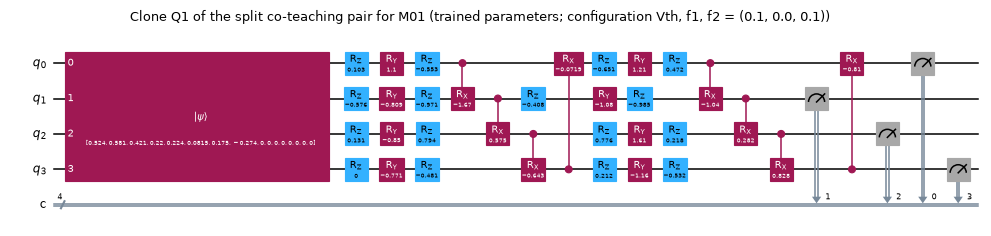

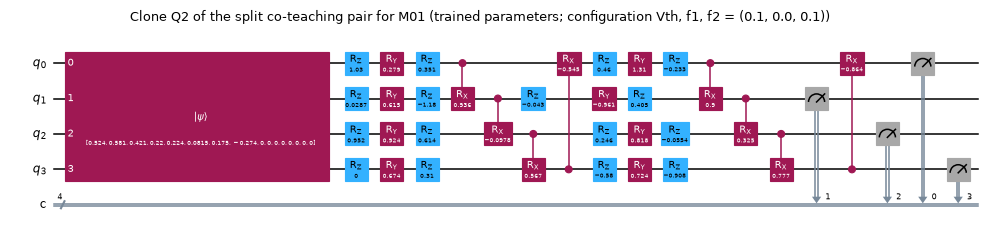

max |class score Qiskit - PyTorch| over 100 test images: 1.0e-12;  identical decisions: True
                                                                                                         0
model                               victim = every clone (Base, QLeak member, CoT/CoT-E/split pair Q1, Q2)
qubits                                                                                                   4
depth (logical, VQC only)                                                                               14
depth (with encoding, id, measure)                                                                      16
depth (basis gates rx/ry/rz/cx)                                                                         49
1-qubit-gate params                                                                                     24
2-qubit-gate (CRX) params                                                                                8
trainable params                                   

In [21]:
from IPython.display import display
t_c, s_c = "M01", SEEDS[0]; tci = TIDX[t_c]
mod = MODELS[(s_c, t_c)]; amp0 = TD[t_c]["A_te"][0].astype(complex)

# 1) the circuit the QNN-as-a-Service executes for one query of the victim (this is the object sent to Aer in Section 4)
par_v = VIC[t_c]["params"]
qc_victim = cloud_circuit(amp0, var_circuit(par_v))                                  # logical circuit: encoding, noisy-id, VQC, measurement
qc_victim_exec = cloud_circuit(amp0, transpile(var_circuit(par_v), basis_gates=CLOUD_BASIS, optimization_level=0))     # as executed in the cloud's basis gates
fig = qc_victim.draw("mpl", fold=45, scale=0.55); fig.suptitle(f"Victim QNN of {t_c} as executed by the simulated cloud (set_statevector = amplitude encoding, id = noisy encoding, then 2 VQC layers and measurement)", fontsize=9)
display(fig); plt.close(fig)

# 2) the two clones of the split co-teaching pair (trained parameters), drawn from the same gate list the PyTorch simulator runs
def clone_circuit(params):
    qc = QuantumCircuit(N_QUBITS, N_QUBITS); qc.initialize(amp0 / np.linalg.norm(amp0), range(N_QUBITS))
    qc.compose(var_circuit(params), inplace=True); qc.measure(range(N_QUBITS), range(N_QUBITS)); return qc
for name, par in [("Q1", mod["Q1"]), ("Q2", mod["Q2"])]:
    fig = clone_circuit(par).draw("mpl", fold=45, scale=0.55); fig.suptitle(f"Clone {name} of the split co-teaching pair for {t_c} (trained parameters; configuration Vth, f1, f2 = {mod['cfg']})", fontsize=9)
    display(fig); plt.close(fig)

# 3) equivalence: the trained clone evaluated with Qiskit's exact Statevector gives the same class decisions as the PyTorch model used in training
chk = torch.tensor(TD[t_c]["A_te"][:100])
mq = BQNN(1, N_QUBITS, N_LAYERS, [0]); mq.params.data = torch.tensor(mod["Q1"])[None].clone()
with torch.no_grad(): sc_torch = head(mq(chk[None]))[0].numpy()
sc_qiskit = np.array([[sum(z[:2]), sum(z[2:])] for z in (qiskit_z(v, mod["Q1"]) for v in chk.numpy())])
print(f"max |class score Qiskit - PyTorch| over 100 test images: {np.abs(sc_qiskit - sc_torch).max():.1e};  identical decisions: {bool((sc_qiskit.argmax(1) == sc_torch.argmax(1)).all())}")
assert np.abs(sc_qiskit - sc_torch).max() < 1e-8 and (sc_qiskit.argmax(1) == sc_torch.argmax(1)).all()

# 4) sizes of every distinct architecture (victim, Base, QLeak members, CoT, CoT-E and both networks of the split co-teaching pair share one architecture)
ops = qc_victim.count_ops(); ops_exec = qc_victim_exec.count_ops()
arch = pd.DataFrame([
    {"model": "victim = every clone (Base, QLeak member, CoT/CoT-E/split pair Q1, Q2)", "qubits": N_QUBITS, "depth (logical, VQC only)": var_circuit(par_v).depth(),
     "depth (with encoding, id, measure)": qc_victim.depth(), "depth (basis gates rx/ry/rz/cx)": qc_victim_exec.depth(),
     "1-qubit-gate params": n_params(4, 2)[0], "2-qubit-gate (CRX) params": n_params(4, 2)[1], "trainable params": sum(n_params(4, 2)),
     "gates after the encoding": {k: v for k, v in var_circuit(par_v).count_ops().items()}}])
print(arch.T.to_string())
print(f"\nSplit co-teaching trains TWO such circuits (Q1 and Q2): {2 * sum(n_params(4, 2))} trainable parameters; QuantumLeak and CoT-E train {ENSEMBLE_SIZE} (and {2 * ENSEMBLE_SIZE}) of them.")
print("Assumptions where the paper is silent: read-out = <Z0>+<Z1> versus <Z2>+<Z3> of the 4 qubits; the CRX gates form a ring (q -> q+1 mod 4); 8 PCA numbers are zero-padded to 16 amplitudes; the cloud's amplitude-encoding circuit is represented by one noisy id gate per qubit.")


## 10. Optional: the victim on real IBM hardware

The paper ran on IBM Quebec. If you have an IBM Quantum account you can put its API token into `IBM_TOKEN` in the configuration cell and re-run the cell below: it sends 50 M01 test images to the least busy real backend with the M01 victim's circuit and prints
the accuracy next to the ideal one. With an empty token (the default) the cell is skipped. This cell was **not executed** while preparing the notebook (no account, no budget); everything else is independent of it.

In [22]:
if not IBM_TOKEN:
    print("IBM_TOKEN is empty -> real-hardware cell skipped (the simulated cloud above is used everywhere).")
else:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
    backend = service.least_busy(operational=True, simulator=False)
    amps = TD["M01"]["A_te"][:50]
    circs = []
    for v in amps:
        qc = QuantumCircuit(4, 4); qc.initialize(v, range(4)); qc.compose(var_circuit(VIC["M01"]["params"]), inplace=True); qc.measure(range(4), range(4)); circs.append(qc)
    isa = transpile(circs, backend=backend, optimization_level=1)
    res = SamplerV2(mode=backend).run(isa, shots=SHOTS).result()
    raw = np.array([sum(c * SGN[int(k, 2)] for k, c in res[i].data.c.get_counts().items()) / SHOTS for i in range(len(circs))])
    acc = (head(torch.tensor(raw)).argmax(1).numpy() == TD["M01"]["y_te"][:50]).mean()
    print(f"{backend.name}: M01 victim accuracy on 50 test images {100 * acc:.1f} % (ideal {100 * VIC['M01']['ideal_acc']:.1f} %)")


IBM_TOKEN is empty -> real-hardware cell skipped (the simulated cloud above is used everywhere).


## 11. Side by side with the paper: a verdict for every claim

Verdicts use the rule of this project: *reproduced* when the value lies within 2 accuracy points (or the stated qualitative relation holds), *not reached* or *exceeded* with the gap otherwise, *cannot be checked* when the quantity is not observable here.

In [23]:
A = lambda m, t: float(acc_tab.loc[m, t])
OURS, DEF = "Split co-teaching (this paper, tuned)", "Split co-teaching (paper defaults)"
VERD = []
def claim(cid, text, paper, here, verdict, note=""):
    VERD.append({"#": cid, "claim in the paper": text, "paper": paper, "this notebook": here, "verdict": verdict, "note": note})
def within(x, target, tol): return abs(x - target) <= tol

# C1 victim accuracy
v1 = 100 * VIC["M01"]["ideal_acc"]
claim("C1", "noise-free victim QNN on MNIST (M01) reaches 98.8 % (Sec. 3.1)", "98.8 %", f"{v1:.1f} %", "reproduced" if within(v1, 98.8, 2) else ("not reached" if v1 < 98.8 else "exceeded"),
      "different PCA/amplitude-encoding details and a CPU simulator")
# C2-C4 observations 1-3 (Fig. 2, M01)
b, q, c, ce = A("Base (CloudLeak)", "M01"), A("QLeak (QuantumLeak)", "M01"), A("CoT (classical co-teaching)", "M01"), A("CoT-E (QuantumLeak + co-teaching)", "M01")
claim("C2", "Obs-1: QuantumLeak is < 2.5 points better than Base under fluctuating noise (Fig. 2: 87.5 vs 86.7)", "+0.8 (< 2.5)", f"{q - b:+.1f}", "reproduced" if q - b < 2.5 else "not reached", f"Base {b:.1f}, QLeak {q:.1f}; Base was used to fit the noise scale")
claim("C3", "Obs-2: classical co-teaching beats QuantumLeak by 1.8 points (Fig. 2: 89.3 vs 87.5)", "+1.8", f"{c - q:+.1f}", "reproduced" if (c - q > 0 and within(c - q, 1.8, 2.0)) else ("not reached" if c - q <= 0 else "exceeded"), f"CoT {c:.1f}, QLeak {q:.1f}")
claim("C4", "Obs-3: adding the QuantumLeak ensemble to co-teaching (CoT-E) is worse than plain co-teaching (88.3 vs 89.3)", "-1.0", f"{ce - c:+.1f}", "reproduced" if ce < c else "not reached", f"CoT-E {ce:.1f}, CoT {c:.1f}")
# C5 observation 4
gap = OBS4["auc_classical"] - OBS4["auc_quantum"]
claim("C5", "Obs-4: small loss separates clean from noisy labels for a classical model but not for a QNN (Fig. 3)", "classical separable, quantum not",
      f"AUROC classical {OBS4['auc_classical']:.2f}, quantum {OBS4['auc_quantum']:.2f}", "reproduced" if (gap >= 0.1 and OBS4["auc_quantum"] <= 0.6) else "not reached",
      "the 'noisy' label is defined here as 'differs from the noise-free victim'; a different definition gives different AUROCs")
# C6 headline accuracy gains
gl = (acc_tab.loc[OURS, TASKS] - acc_tab.loc["QLeak (QuantumLeak)", TASKS]).astype(float); gb = (acc_tab.loc[OURS, TASKS] - acc_tab.loc["Base (CloudLeak)", TASKS]).astype(float)
claim("C6", "split co-teaching beats QuantumLeak by 0.1 ... 3.7 points on every task (Fig. 6)", "+0.1 ... +3.7", f"{gl.min():+.1f} ... {gl.max():+.1f} (mean {gl.mean():+.1f})",
      "reproduced" if (gl.min() > 0 and gl.max() <= 3.7 + 2) else ("exceeded" if gl.min() > 0 else "not reached"), "tuned on the validation set; per task: " + ", ".join(f"{t} {x:+.1f}" for t, x in gl.items()))
claim("C7", "split co-teaching beats the classical Base attack by 6.5 ... 9.5 points (abstract, Fig. 6)", "+6.5 ... +9.5", f"{gb.min():+.1f} ... {gb.max():+.1f} (mean {gb.mean():+.1f})",
      "reproduced" if (gb.mean() >= 6.5 - 2 and gb.mean() <= 9.5 + 2) else ("exceeded" if gb.mean() > 9.5 + 2 else "not reached"), "per task: " + ", ".join(f"{t} {x:+.1f}" for t, x in gb.items()))
others = ["Base (CloudLeak)", "QLeak (QuantumLeak)", "CoT (classical co-teaching)", "CoT-E (QuantumLeak + co-teaching)"]
best_all = [(t, acc_tab.loc[OURS, t] >= acc_tab.loc[others, t].max()) for t in TASKS]
claim("C8", "split co-teaching gives the most accurate clone on all tasks (Fig. 6)", f"all {len(TASKS)} tasks", f"{sum(b_ for _, b_ in best_all)} of {len(TASKS)} tasks",
      "reproduced" if all(b_ for _, b_ in best_all) else "not reached", "best of Base, QLeak, CoT, CoT-E: " + ", ".join(f"{t} {'yes' if b_ else 'no'}" for t, b_ in best_all))
claim("C9", "absolute accuracy of the split co-teaching clone on M01 is about 91 ... 92.6 % (Figs. 7-9)", "91.7 % (Vth 0.1, f1 0, f2 0.3)", f"{A(DEF, 'M01'):.1f} % at the paper defaults, {A(OURS, 'M01'):.1f} % tuned",
      "reproduced" if within(A(DEF, "M01"), 91.7, 2) else ("not reached" if A(DEF, "M01") < 91.7 else "exceeded"), "the noise strength is calibrated on Base (86.7 %), so absolute levels follow from that choice")
# C10-C12 sensitivity
sv = SW[SW.sweep == "Vth"].groupby("vth").acc.mean(); sf1 = SW[SW.sweep == "f1"].groupby("f1").acc.mean(); sf2 = SW[SW.sweep == "f2"].groupby("f2").acc.mean()
claim("C10", "accuracy peaks at an interior Vth (0.15, 92.6 %) and falls on both sides (Fig. 7)", "peak at Vth = 0.15", f"peak at Vth = {sv.idxmax()} ({sv.max():.1f} %); values " + ", ".join(f"{k}: {x:.1f}" for k, x in sv.items()),
      "reproduced" if (sv.idxmax() == 0.15) else ("reproduced (interior peak, other position)" if sv.idxmax() not in (sv.index.min(), sv.index.max()) else "not reached"), "")
sh = SW[(SW.sweep == "Vth") & (SW.vth == 0.15)].share_robust.mean() if (SW.vth == 0.15).any() else np.nan
claim("C11", "at Vth = 0.15, 72.6 % of the M01 queries fall into the robust set D_r (Sec. 5.2)", "72.6 %", f"{sh:.1f} %" if sh == sh else "n/a", ("reproduced" if within(sh, 72.6, 10) else "not reached") if sh == sh else "cannot be checked",
      "depends on how the variation is normalised (here: divided by its maximum) and on the noise model")
claim("C12", "f1 has little effect (91.7 ... 92.7 %, Fig. 8)", f"spread {92.7 - 91.7:.1f} points", f"spread {sf1.max() - sf1.min():.1f} points", "reproduced" if (sf1.max() - sf1.min()) <= 2.0 else "not reached", "values " + ", ".join(f"{k}: {x:.1f}" for k, x in sf1.items()))
claim("C13", "a larger f2 helps: 90.2 % (f2 = 0.1) to 92.0 % (f2 = 0.5) (Fig. 9)", "+1.8 points", f"{sf2.iloc[-1] - sf2.iloc[0]:+.1f} points", "reproduced" if sf2.iloc[-1] - sf2.iloc[0] > 0 else "not reached", "values " + ", ".join(f"{k}: {x:.1f}" for k, x in sf2.items()))
claim("C14", "gate errors on a NISQ device change by 31.2 % (1QG) and 10.3 % (2QG) within a day (Table 1)", "31.2 % / 10.3 %", "simulated drift 12 ... 45 %", "cannot be checked", "real calibration data of IBM Quebec are not available here; the simulated drift is a model assumption")
cmp_df = pd.DataFrame(VERD)
pd.set_option("display.max_colwidth", 120)
print(cmp_df[["#", "claim in the paper", "paper", "this notebook", "verdict"]].to_string(index=False))
print("\nNotes:"); [print(f" {r['#']}: {r['note']}") for r in VERD if r["note"]]
print("\nVerdict counts:", cmp_df.verdict.value_counts().to_dict())


  #                                                                                           claim in the paper                            paper                                                                                this notebook           verdict
 C1                                               noise-free victim QNN on MNIST (M01) reaches 98.8 % (Sec. 3.1)                           98.8 %                                                                                       98.3 %        reproduced
 C2           Obs-1: QuantumLeak is < 2.5 points better than Base under fluctuating noise (Fig. 2: 87.5 vs 86.7)                     +0.8 (< 2.5)                                                                                         -0.8        reproduced
 C3                          Obs-2: classical co-teaching beats QuantumLeak by 1.8 points (Fig. 2: 89.3 vs 87.5)                             +1.8                                                                                    

## 12. Reading the paper critically

**What this notebook found.** With a simulated cloud whose only fitted number is the noise scale, the qualitative picture of the paper is reproduced: the clone trained with split co-teaching is more accurate than the QuantumLeak and the classical (Base) clones on all five tasks (and than all four baselines on four of them)
and about 3 points better on average (+1.7 ... +6.7 over QuantumLeak, +1.6 ... +5.0 over Base, validation-tuned Vth, f1, f2), classical co-teaching also helps a little, and the QuantumLeak ensemble inside co-teaching (CoT-E) hurts.
The size of the gain over Base (3.0 points on average) is below the paper's 6.5 ... 9.5, the dependence on Vth, f1 and f2 shown in Figs. 7 to 9 is not visible (all points of the sweeps lie within about 3 points of each other, the standard deviation of one run is 4 to 5 points), and the absolute M01 accuracy of the paper (about 91.7 %) is approached (90.6 % at the paper's default setting, 90.3 % tuned).

**1. The statistics are thin, in the paper and here.** The paper reports single runs on hardware without error bars. Its own Figs. 7 and 9 contain the same configuration (Vth = 0.1, f1 = 0, f2 = 0.1) with 91.8 % and 90.2 %, a 1.6-point difference that is as large as the lower end of the claimed gain over QuantumLeak (0.1 ... 3.7).
Here two simulated days and two restarts per cell leave standard deviations of up to 10 points between seeds for individual methods (second table of Section 8); the means over five tasks are better determined but a difference of 1 or 2 points between two methods is not significant. Exercise 5 asks for the missing confidence intervals.

**2. The advantage is not shown to come from the split.** The ablation of Section 9b trains the pair with the paper's defaults, then with a *random* score that puts the same share of images into D_r, then with one forget rate of the same average and finally without any forgetting:
87.7 %, 87.8 %, 88.2 % and 86.8 % on M01 (standard deviation 4 to 5 points). The data cannot separate these four, so what helps in this simulation is co-teaching with forgetting, not the choice of *which* samples are forgotten. The premise of the split is also only weakly supported: the label variation finds images with a wrong label with an AUROC of 0.52 to 0.61 (Section 5) and the share of wrong labels in D_r and D_v differs by a few points at most (for some tasks D_r even holds more wrong labels).
This is not a refutation, because the nature of the noise matters. In our model much of the label noise is a fixed, systematic error (coherent over-rotation, read-out asymmetry), which makes the same images wrong in every round; the paper's real device may fluctuate more.
Note also that the same first author's follow-up paper on CopyQNN (QNN_ModelExtraction_Fu2025.ipynb in this folder) assumes the **opposite**: there, wrongly labelled images sit at *low* variance and the high-variance images are kept.

**3. Observation 4 depends on the definition of "noisy".** We call a label noisy when it differs from the noise-free victim's label. With that definition the classical loss separates noisy from correct labels (AUROC 0.80) and the QNN's loss does not (0.47), as the paper reports. But a QNN with 32 parameters cannot memorise individual wrong labels in the first place; it fits the *systematic* part of the noise,
so wrong labels get no larger loss than correct ones. For such a small model the usual argument for co-teaching (preventing memorisation of noisy labels) is weak, and the same fact explains why classical models trained on exactly the same stolen data (logistic regression 87.3 % on average, random forest 84.4 %) are more accurate than every QNN clone here.
The paper does not report such a classical substitute because its "classical attack" is CloudLeak applied to a QNN clone; if the goal is only to *copy the input-output behaviour* of a 4-qubit QNN, a classical model is the stronger attacker in this setting.

**4. Tuning is not symmetric.** Split co-teaching has three hyper-parameters (Section 7 tunes them on 500 labelled validation images over 9 configurations with 2 restarts each), CoT has one (tau, 3 values), Base and QuantumLeak none. The "paper defaults" row avoids the advantage of tuning (79.7 % mean, 1.0 points above Base) and is the fairer comparison; the tuned row (81.7 %) is optimistic.
The paper does not say how Vth, f1 and f2 were chosen or what the 500 validation images are used for, and a threat model in which the attacker owns 500 correctly labelled images is more generous than a pure black box.

**5. Calibration and the simulated cloud.** The noise scale was fitted so that the Base clone of M01 reaches the paper's 86.7 % (Section 4b), which makes claim C2 a fit; the shape of the noise (static part, `DRIFT = 0.5`, coherent over-rotation, asymmetric read-out) is an assumption, and Table 1 of the paper (gate-error drift) cannot be checked without real calibration data.
The victim of M78 reaches only 87.3 %, probably because only 8 PCA numbers enter a 4-qubit circuit with 32 parameters; the paper does not report victim accuracies other than 98.8 % for MNIST.

**6. A lesson from the implementation.** In a batch of co-teaching pairs, pairs with a small D_r or D_v run out of mini-batches earlier than others. If the optimiser keeps stepping for them, Adam turns even the tiny weight-decay gradient and its leftover momentum into full-size steps and quietly destroys those clones: in an earlier version of this notebook that effect made "two plain QNNs without forgetting" drop to 55 % instead of the 83 to 89 % of the plain Base clones.
`MaskedAdam` leaves such pairs untouched and the test in Section 7a guards against the regression. Any batched implementation of a method with data-dependent loop lengths deserves such a test.

## 13. Exercises

1. **Noise strength.** Change `CAL_LEVELS` or fix `NOISE_LEVEL` by hand (for example half and double the fitted value) and re-run Sections 5 to 9. For which noise strength does split co-teaching help most over Base and QuantumLeak, and where do the methods become indistinguishable?
2. **Query budget.** The paper's selling point is a lower budget. Re-run with `N_QUERY` in 500, 1500, 3000 and 6000 and with `M_ROUNDS` in 2, 3, 5, 10 (the rounds are always spread over 24 hours). Plot accuracy against the number of labels `N_QUERY * M_ROUNDS`. How many labels does each method need to come within 3 points of the clean-label clone?
3. **A different split rule.** Replace `variance_score` by the largest range (max minus min) of the probabilities, by the number of label flips between rounds, or by the entropy of the round-averaged probability. Does the AUROC in Section 5 for finding wrong labels improve, and does the accuracy of Section 8 follow?
4. **A defence.** A provider could return only hard labels, round the probabilities to one decimal, or answer every image only once per day. Modify `cloud_answer` / `to_probs` accordingly and measure how much of the advantage of split co-teaching survives (note that with hard labels the variation score takes only a few values).
5. **Statistics.** The paper's gains over QuantumLeak (0.1 ... 3.7 points) are as large as the difference between two of its own runs of the same configuration (compare the Vth = 0.1 point of Fig. 7 with the f2 = 0.1 point of Fig. 9). Increase `SEEDS` to 10 and compute a paired bootstrap confidence interval for the gain over QLeak and over CoT per task. Which differences are significant?